# EXPLORATORY DATA ANALYSIS LAB — BCSE331P
**Name:** Adharsh  
**Reg. No:** 23BDS0029

**Video Link:** https://drive.google.com/file/d/1B3sv6_ShANtQphafbmQktTSvDC0QpEh4/view?usp=sharing

Compiled R code for Assessments I, II, III, V, VI, VII, VIII and IX.  
Dataset used in assessments: `GSS7402.xlsx` (place it in the working directory, or edit `data_path` below).

In [142]:

pkgs <- c("readxl","dplyr","tidyr","ggplot2","stringr","forcats","GGally","zoo",
          "forecast","e1071","corrplot","ggfortify","FactoMineR","factoextra","ggrepel")
for (p in pkgs) {
  if (!requireNamespace(p, quietly = TRUE)) install.packages(p, repos = "https://cloud.r-project.org")
}
library(readxl); library(dplyr); library(tidyr); library(ggplot2)
library(stringr); library(forcats); library(GGally); library(zoo)


data_path <- "/GSS7402.xlsx"

---
# ASSESSMENT I — Merging and Data Transformation
## Part 1: Merging / Concatenating data frames

In [12]:
dataframe1 <- data.frame(
  ProductID = 101:110,
  NameofProd = c("Laptop", "Mouse", "Keyboard", "Monitor", "Printer",
                 "Webcam", "Speaker", "Headset", "Router", "Tablet"),
  Price    = c(55000, 800, 1500, 9500, 6500,
               2200, 3000, 2500, 1800, 21000),
  stringsAsFactors = FALSE
)
dataframe2 <- data.frame(
  ProductID      = 105:114,
  Company_Location = c("Chennai", "Bangalore", "Mumbai", "Delhi", "Pune",
                       "Hyderabad", "Kolkata", "Ahmedabad", "Jaipur", "Kochi"),
  stringsAsFactors = FALSE
)
dataframe3 <- data.frame(
  ProductID = 201:210,
  NameofProd = c("Charger", "PowerBank", "SSD", "HDD", "GraphicsCard",
                 "RAM", "Motherboard", "SmartWatch", "Earbuds", "Drone"),
  Price    = c(1200, 2000, 4500, 3200, 45000,
               3500, 12000, 6000, 2800, 35000),
  stringsAsFactors = FALSE
)
cat("\n--- dataframe1 ---\n"); print(dataframe1)
cat("\n--- dataframe2 ---\n"); print(dataframe2)
cat("\n--- dataframe3 ---\n"); print(dataframe3)


--- dataframe1 ---
   ProductID NameofProd Price
1        101     Laptop 55000
2        102      Mouse   800
3        103   Keyboard  1500
4        104    Monitor  9500
5        105    Printer  6500
6        106     Webcam  2200
7        107    Speaker  3000
8        108    Headset  2500
9        109     Router  1800
10       110     Tablet 21000

--- dataframe2 ---
   ProductID Company_Location
1        105          Chennai
2        106        Bangalore
3        107           Mumbai
4        108            Delhi
5        109             Pune
6        110        Hyderabad
7        111          Kolkata
8        112        Ahmedabad
9        113           Jaipur
10       114            Kochi

--- dataframe3 ---
   ProductID   NameofProd Price
1        201      Charger  1200
2        202    PowerBank  2000
3        203          SSD  4500
4        204          HDD  3200
5        205 GraphicsCard 45000
6        206          RAM  3500
7        207  Motherboard 12000
8        208   SmartWatc

In [13]:
appended_df <- rbind(dataframe1, dataframe3)
cat("\n--- Appended dataframe1 + dataframe3 ---\n")
print(appended_df)

concat_rows <- rbind(dataframe1, dataframe3)
cat("\n--- Row-wise concatenation (rbind) ---\n")
print(concat_rows)

concat_ids <- c(dataframe1$ProductID, dataframe2$ProductID, dataframe3$ProductID)
cat("\n--- Concatenated ProductID vector (c()) ---\n")
print(concat_ids)

concat_cols <- cbind(dataframe1, Company_Location = dataframe2$Company_Location)
cat("\n--- Column-wise concatenation (cbind) of dataframe1 + dataframe2$Company_Location ---\n")
print(concat_cols)


--- Appended dataframe1 + dataframe3 ---
   ProductID   NameofProd Price
1        101       Laptop 55000
2        102        Mouse   800
3        103     Keyboard  1500
4        104      Monitor  9500
5        105      Printer  6500
6        106       Webcam  2200
7        107      Speaker  3000
8        108      Headset  2500
9        109       Router  1800
10       110       Tablet 21000
11       201      Charger  1200
12       202    PowerBank  2000
13       203          SSD  4500
14       204          HDD  3200
15       205 GraphicsCard 45000
16       206          RAM  3500
17       207  Motherboard 12000
18       208   SmartWatch  6000
19       209      Earbuds  2800
20       210        Drone 35000

--- Row-wise concatenation (rbind) ---
   ProductID   NameofProd Price
1        101       Laptop 55000
2        102        Mouse   800
3        103     Keyboard  1500
4        104      Monitor  9500
5        105      Printer  6500
6        106       Webcam  2200
7        107      Spea

In [14]:
merged_df <- merge(dataframe1, dataframe2, by = "ProductID")
cat("\n--- merge(dataframe1, dataframe2, by = 'ProductID') ---\n")
print(merged_df)

inner_join_df <- merge(dataframe1, dataframe2, by = "ProductID")
cat("\n--- Inner Join ---\n")
print(inner_join_df)

left_join_df <- merge(dataframe1, dataframe2, by = "ProductID", all.x = TRUE)
cat("\n--- Left Join ---\n")
print(left_join_df)

right_join_df <- merge(dataframe1, dataframe2, by = "ProductID", all.y = TRUE)
cat("\n--- Right Join ---\n")
print(right_join_df)

full_outer_join_df <- merge(dataframe1, dataframe2, by = "ProductID", all = TRUE)
cat("\n--- Full Outer Join ---\n")
print(full_outer_join_df)


--- merge(dataframe1, dataframe2, by = 'ProductID') ---
  ProductID NameofProd Price Company_Location
1       105    Printer  6500          Chennai
2       106     Webcam  2200        Bangalore
3       107    Speaker  3000           Mumbai
4       108    Headset  2500            Delhi
5       109     Router  1800             Pune
6       110     Tablet 21000        Hyderabad

--- Inner Join ---
  ProductID NameofProd Price Company_Location
1       105    Printer  6500          Chennai
2       106     Webcam  2200        Bangalore
3       107    Speaker  3000           Mumbai
4       108    Headset  2500            Delhi
5       109     Router  1800             Pune
6       110     Tablet 21000        Hyderabad

--- Left Join ---
   ProductID NameofProd Price Company_Location
1        101     Laptop 55000             <NA>
2        102      Mouse   800             <NA>
3        103   Keyboard  1500             <NA>
4        104    Monitor  9500             <NA>
5        105    Printer  

## Part 2: Normalization / Data transformation

In [15]:
adharsh <- c(29, 45, 12, 67, 88, 33, 91, 5, 76, 52)
print(adharsh)

normalize_range <- function(x, new_min, new_max) {
  ((x - min(x)) / (max(x) - min(x))) * (new_max - new_min) + new_min
}
adharsh_norm_neg3_3 <- normalize_range(adharsh, -3, 3)
cat("\n--- Normalized to [-3, +3] ---\n")
print(round(adharsh_norm_neg3_3, 4))

adharsh_norm_neg1_1 <- normalize_range(adharsh, -1, 1)
cat("\n--- Normalized to [-1, +1] ---\n")
print(round(adharsh_norm_neg1_1, 4))

adharsh_norm_0_1 <- normalize_range(adharsh, 0, 1)
cat("\n--- Min-Max Normalized to [0, 1] ---\n")
print(round(adharsh_norm_0_1, 4))

adharsh_zscore <- (adharsh - mean(adharsh)) / sd(adharsh)
cat("\n--- Z-score transformed ---\n")
print(round(adharsh_zscore, 4))

j <- ceiling(log10(max(abs(adharsh))))
adharsh_decimal_scaled <- adharsh / (10^j)
cat(paste0("\n--- Decimal Scaling Normalization (j = ", j, ") ---\n"))
print(round(adharsh_decimal_scaled, 4))

 [1] 29 45 12 67 88 33 91  5 76 52

--- Normalized to [-3, +3] ---
 [1] -1.3256 -0.2093 -2.5116  1.3256  2.7907 -1.0465  3.0000 -3.0000  1.9535
[10]  0.2791

--- Normalized to [-1, +1] ---
 [1] -0.4419 -0.0698 -0.8372  0.4419  0.9302 -0.3488  1.0000 -1.0000  0.6512
[10]  0.0930

--- Min-Max Normalized to [0, 1] ---
 [1] 0.2791 0.4651 0.0814 0.7209 0.9651 0.3256 1.0000 0.0000 0.8256 0.5465

--- Z-score transformed ---
 [1] -0.6842 -0.1579 -1.2434  0.5658  1.2566 -0.5526  1.3553 -1.4737  0.8618
[10]  0.0724

--- Decimal Scaling Normalization (j = 2) ---
 [1] 0.29 0.45 0.12 0.67 0.88 0.33 0.91 0.05 0.76 0.52


---
# ASSESSMENT II — Data Import, Transform and Basic Statistical Analysis

**Q1.** Import the given dataset into R.

In [16]:
df <- read_excel(data_path)

**Q2.** Display the first 10 records.

In [17]:
head(df, 10)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,0,25,14,2002,1,NA,cauc,no,no,no
2,1,30,13,2002,4,19,cauc,yes,no,no
3,1,55,2,2002,1,27,cauc,no,no,yes
4,2,57,16,2002,1,22,cauc,no,no,no
5,2,71,12,2002,6,29,cauc,yes,no,no
6,0,19,13,2002,1,NA,other,yes,no,no
7,0,71,12,2002,1,NA,cauc,no,no,no
8,0,30,12,2002,5,NA,other,no,no,yes
9,1,35,12,2002,0,21,cauc,yes,no,yes


**Q3.** Display the last 10 records.

In [18]:
tail(df, 10)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
9111,0,24,13,1998,1,NA,other,yes,no,no
9112,2,49,18,1998,3,25,cauc,no,no,no
9113,2,68,12,1998,2,25,cauc,no,no,no
9114,3,81,12,1998,4,19,cauc,no,no,no
9115,1,49,14,1998,1,34,cauc,no,no,no
9116,3,30,12,1998,2,21,cauc,no,no,no
9117,2,37,12,1998,3,23,cauc,no,no,no
9118,3,59,9,1998,5,20,cauc,no,no,no
9119,2,73,14,1998,5,22,cauc,yes,no,no


**Q4.** Total number of rows and columns.

In [19]:
dim(df)
cat("Number of rows:", nrow(df), "\n")
cat("Number of columns:", ncol(df), "\n")

[1] 9120   11

Number of rows: 9120 
Number of columns: 11 


**Q5.** Names of all variables (columns).

In [20]:
colnames(df)

[1] "rownames"      "kids"          "age"           "education"    
 [5] "year"          "siblings"      "agefirstbirth" "ethnicity"    
 [9] "city16"        "lowincome16"   "immigrant"

**Q6.** Data type (structure) of each variable.

In [21]:
str(df)

tibble [9,120 × 11] (S3: tbl_df/tbl/data.frame)
 $ rownames     : num [1:9120] 1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num [1:9120] 0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num [1:9120] 25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num [1:9120] 14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num [1:9120] 2002 2002 2002 2002 2002 ...
 $ siblings     : num [1:9120] 1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num [1:9120] NA 19 27 22 29 NA NA NA 21 20 ...
 $ ethnicity    : chr [1:9120] "cauc" "cauc" "cauc" "cauc" ...
 $ city16       : chr [1:9120] "no" "yes" "no" "no" ...
 $ lowincome16  : chr [1:9120] "no" "no" "no" "no" ...
 $ immigrant    : chr [1:9120] "no" "no" "yes" "no" ...


**Q7.** Summary statistics.

In [22]:
summary(df)

    rownames         kids            age          education          year     
 Min.   :   1   Min.   :0.000   Min.   :18.00   Min.   : 0.00   Min.   :1974  
 1st Qu.:2281   1st Qu.:1.000   1st Qu.:31.00   1st Qu.:12.00   1st Qu.:1982  
 Median :4560   Median :2.000   Median :43.00   Median :12.00   Median :1994  
 Mean   :4560   Mean   :2.076   Mean   :46.08   Mean   :12.64   Mean   :1990  
 3rd Qu.:6840   3rd Qu.:3.000   3rd Qu.:59.00   3rd Qu.:14.00   3rd Qu.:1998  
 Max.   :9120   Max.   :8.000   Max.   :89.00   Max.   :20.00   Max.   :2002  
                                                                              
    siblings      agefirstbirth       ethnicity          city16    
 Min.   : 0.000   Min.   : 9.00   Length   :9120   Length   :9120  
 1st Qu.: 2.000   1st Qu.:19.00   N.unique :   2   N.unique :   2  
 Median : 3.000   Median :22.00   N.blank  :   0   N.blank  :   0  
 Mean   : 4.051   Mean   :22.63   Min.nchar:   4   Min.nchar:   2  
 3rd Qu.: 6.000   3rd Qu.:25

**Q8.** Number of missing values in each column (15 values artificially set to NA in `education` and `ethnicity`).

In [23]:
set.seed(123)
df$education[sample(1:nrow(df), 15)] <- NA
df$ethnicity[sample(1:nrow(df), 15)] <- NA
colSums(is.na(df))

rownames          kids           age     education          year 
            0             0             0            15             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808            15             0             0 
    immigrant 
            0

**Q9.** Total number of missing values.

In [24]:
sum(is.na(df))

[1] 5838

**Q10.** Missing values in each column.

In [25]:
sapply(df, function(x) sum(is.na(x)))

rownames          kids           age     education          year 
            0             0             0            15             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808            15             0             0 
    immigrant 
            0

**Q11.** Rows containing at least one missing value.

In [26]:
rows_with_na <- df[!complete.cases(df), ]
head(rows_with_na, 10)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,0,25,14,2002,1,NA,cauc,no,no,no
6,0,19,13,2002,1,NA,other,yes,no,no
7,0,71,12,2002,1,NA,cauc,no,no,no
8,0,30,12,2002,5,NA,other,no,no,yes
15,0,36,17,2002,1,NA,other,yes,no,no
17,0,28,9,2002,4,NA,cauc,no,no,yes
19,0,42,16,2002,3,NA,cauc,no,yes,no
20,0,26,14,2002,3,NA,cauc,yes,no,no
21,0,51,20,2002,1,NA,cauc,no,yes,no


**Q12.** Remove all rows containing missing values.

In [27]:
df_cleaned <- na.omit(df)
head(df_cleaned, 10)
dim(df_cleaned)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
2,1,30,13,2002,4,19,cauc,yes,no,no
3,1,55,2,2002,1,27,cauc,no,no,yes
4,2,57,16,2002,1,22,cauc,no,no,no
5,2,71,12,2002,6,29,cauc,yes,no,no
9,1,35,12,2002,0,21,cauc,yes,no,yes
10,3,51,12,2002,1,20,cauc,yes,no,no
11,6,34,13,2002,5,18,other,yes,no,no
12,2,46,16,2002,5,27,other,yes,no,no
13,2,81,12,2002,7,22,cauc,no,no,no


[1] 3302   11

**Q13.** Replace missing values in a numerical column using the mean.

In [28]:
df_impute <- df
df_impute$agefirstbirth[is.na(df_impute$agefirstbirth)] <- mean(df$agefirstbirth, na.rm = TRUE)

**Q14.** Replace missing values in another numerical column using the median.

In [29]:
df_impute$education[is.na(df_impute$education)] <- median(df$education, na.rm = TRUE)

**Q15.** Replace missing values in a categorical column using the mode.

In [30]:
get_mode <- function(v) {
  v <- v[!is.na(v)]
  uniq_v <- unique(v)
  uniq_v[which.max(tabulate(match(v, uniq_v)))]
}
ethnicity_mode <- get_mode(df$ethnicity)
df_impute$ethnicity[is.na(df_impute$ethnicity)] <- ethnicity_mode
colSums(is.na(df_impute))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0             0             0             0             0 
    immigrant 
            0

**Q16.** Forward filling (`zoo::na.locf`).

In [31]:
df_locf <- df
df_locf$agefirstbirth <- na.locf(df_locf$agefirstbirth, na.rm = FALSE)

**Q17.** Backward filling.

In [32]:
df_locf$agefirstbirth <- na.locf(df_locf$agefirstbirth, fromLast = TRUE, na.rm = FALSE)

**Q18.** Replace remaining missing values with a constant (0 / "Unknown").

In [33]:
df_locf$education[is.na(df_locf$education)] <- 0
df_locf$ethnicity[is.na(df_locf$ethnicity)] <- "Unknown"
colSums(is.na(df_locf))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0             0             0             0             0 
    immigrant 
            0

**Q19.** Remove duplicate records.

In [34]:
df_no_dup <- df_locf[!duplicated(df_locf), ]
cat("Rows before removing duplicates:", nrow(df_locf), "\n")
cat("Rows after removing duplicates:", nrow(df_no_dup), "\n")

Rows before removing duplicates: 9120 
Rows after removing duplicates: 9120 


**Q20.** Convert appropriate variables into factors.

In [35]:
df_no_dup$ethnicity <- as.factor(df_no_dup$ethnicity)
df_no_dup$city16     <- as.factor(df_no_dup$city16)
df_no_dup$lowincome16 <- as.factor(df_no_dup$lowincome16)
df_no_dup$immigrant <- as.factor(df_no_dup$immigrant)
str(df_no_dup)

tibble [9,120 × 11] (S3: tbl_df/tbl/data.frame)
 $ rownames     : num [1:9120] 1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num [1:9120] 0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num [1:9120] 25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num [1:9120] 14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num [1:9120] 2002 2002 2002 2002 2002 ...
 $ siblings     : num [1:9120] 1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num [1:9120] 19 19 27 22 29 29 29 29 21 20 ...
 $ ethnicity    : Factor w/ 3 levels "cauc","other",..: 1 1 1 1 1 2 1 2 1 1 ...
 $ city16       : Factor w/ 2 levels "no","yes": 1 2 1 1 2 2 1 1 2 2 ...
 $ lowincome16  : Factor w/ 2 levels "no","yes": 1 1 1 1 1 1 1 1 1 1 ...
 $ immigrant    : Factor w/ 2 levels "no","yes": 1 1 2 1 1 1 1 2 2 1 ...


**Q21.** Rename columns.

In [36]:
colnames(df_no_dup)[colnames(df_no_dup) == "kids"] <- "num_kids"
colnames(df_no_dup)[colnames(df_no_dup) == "siblings"] <- "num_siblings"
colnames(df_no_dup)

[1] "rownames"      "num_kids"      "age"           "education"    
 [5] "year"          "num_siblings"  "agefirstbirth" "ethnicity"    
 [9] "city16"        "lowincome16"   "immigrant"

**Q22.** Create new derived columns.

In [37]:
df_no_dup$family_size <- df_no_dup$num_kids + df_no_dup$num_siblings

df_no_dup$age_group <- cut(
  df_no_dup$age,
  breaks = c(0, 30, 45, 60, Inf),
  labels = c("Young(<=30)", "Middle(31-45)", "Senior(46-60)", "Elder(60+)")
)
head(df_no_dup[, c("age", "age_group", "num_kids", "num_siblings", "family_size")], 10)

age,age_group,num_kids,num_siblings,family_size
<dbl>,<fct>,<dbl>,<dbl>,<dbl>
25,Young(<=30),0,1,1
30,Young(<=30),1,4,5
55,Senior(46-60),1,1,2
57,Senior(46-60),2,1,3
71,Elder(60+),2,6,8
19,Young(<=30),0,1,1
71,Elder(60+),0,1,1
30,Young(<=30),0,5,5
35,Middle(31-45),1,0,1


**Q23.** Summary statistics using `summary()`.

In [38]:
summary(df_no_dup)

    rownames       num_kids          age          education          year     
 Min.   :   1   Min.   :0.000   Min.   :18.00   Min.   : 0.00   Min.   :1974  
 1st Qu.:2281   1st Qu.:1.000   1st Qu.:31.00   1st Qu.:12.00   1st Qu.:1982  
 Median :4560   Median :2.000   Median :43.00   Median :12.00   Median :1994  
 Mean   :4560   Mean   :2.076   Mean   :46.08   Mean   :12.61   Mean   :1990  
 3rd Qu.:6840   3rd Qu.:3.000   3rd Qu.:59.00   3rd Qu.:14.00   3rd Qu.:1998  
 Max.   :9120   Max.   :8.000   Max.   :89.00   Max.   :20.00   Max.   :2002  
  num_siblings    agefirstbirth     ethnicity    city16     lowincome16
 Min.   : 0.000   Min.   : 9.00   cauc   :7323   no :5246   no :7182   
 1st Qu.: 2.000   1st Qu.:21.00   other  :1782   yes:3874   yes:1938   
 Median : 3.000   Median :30.00   Unknown:  15                         
 Mean   : 4.051   Mean   :26.18                                        
 3rd Qu.: 6.000   3rd Qu.:30.00                                        
 Max.   :35.000

**Q24.** Minimum and maximum values.

In [39]:
min_age <- min(df_no_dup$age, na.rm = TRUE)
max_age <- max(df_no_dup$age, na.rm = TRUE)
cat("Minimum age:", min_age, "\n")
cat("Maximum age:", max_age, "\n")

Minimum age: 18 
Maximum age: 89 


**Q25.** Range.

In [40]:
age_range <- range(df_no_dup$age, na.rm = TRUE)
cat("Range of age:", age_range, "\n")
cat("Range span (max - min):", diff(age_range), "\n")

Range of age: 18 89 
Range span (max - min): 71 


**Q26.** Variance.

In [41]:
age_variance <- var(df_no_dup$age, na.rm = TRUE)
cat("Variance of age:", age_variance, "\n")

Variance of age: 321.2658 


**Q27.** Standard deviation.

In [42]:
age_sd <- sd(df_no_dup$age, na.rm = TRUE)
cat("Standard Deviation of age:", age_sd, "\n")

Standard Deviation of age: 17.92389 


**Q28.** Interquartile range (IQR).

In [43]:
age_iqr <- IQR(df_no_dup$age, na.rm = TRUE)
cat("IQR of age:", age_iqr, "\n")

IQR of age: 28 


---
# ASSESSMENT III — Data Cleaning and Univariate Analysis
Packages: dplyr, tidyr, ggplot2, stringr, forcats (loaded in the setup cell).

**Q1.** Import the dataset.

In [44]:
df <- read_excel(data_path)
str(df)
dim(df)

tibble [9,120 × 11] (S3: tbl_df/tbl/data.frame)
 $ rownames     : num [1:9120] 1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num [1:9120] 0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num [1:9120] 25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num [1:9120] 14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num [1:9120] 2002 2002 2002 2002 2002 ...
 $ siblings     : num [1:9120] 1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num [1:9120] NA 19 27 22 29 NA NA NA 21 20 ...
 $ ethnicity    : chr [1:9120] "cauc" "cauc" "cauc" "cauc" ...
 $ city16       : chr [1:9120] "no" "yes" "no" "no" ...
 $ lowincome16  : chr [1:9120] "no" "no" "no" "no" ...
 $ immigrant    : chr [1:9120] "no" "no" "yes" "no" ...


[1] 9120   11

**Q2.** First and last six records.

In [45]:
head(df, 6)
tail(df, 6)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,0,25,14,2002,1,NA,cauc,no,no,no
2,1,30,13,2002,4,19,cauc,yes,no,no
3,1,55,2,2002,1,27,cauc,no,no,yes
4,2,57,16,2002,1,22,cauc,no,no,no
5,2,71,12,2002,6,29,cauc,yes,no,no
6,0,19,13,2002,1,NA,other,yes,no,no


rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
9115,1,49,14,1998,1,34,cauc,no,no,no
9116,3,30,12,1998,2,21,cauc,no,no,no
9117,2,37,12,1998,3,23,cauc,no,no,no
9118,3,59,9,1998,5,20,cauc,no,no,no
9119,2,73,14,1998,5,22,cauc,yes,no,no
9120,0,40,12,1998,4,NA,cauc,no,no,no


**Q3.** Total number of missing values.

In [46]:
total_missing <- sum(is.na(df))
cat("Total missing values in the dataset:", total_missing, "\n")
colSums(is.na(df))

Total missing values in the dataset: 5808 


rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808             0             0             0 
    immigrant 
            0

**Q4.** Records containing at least one missing value.

In [47]:
records_with_na <- df[!complete.cases(df), ]
head(records_with_na, 10)
nrow(records_with_na)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,0,25,14,2002,1,NA,cauc,no,no,no
6,0,19,13,2002,1,NA,other,yes,no,no
7,0,71,12,2002,1,NA,cauc,no,no,no
8,0,30,12,2002,5,NA,other,no,no,yes
15,0,36,17,2002,1,NA,other,yes,no,no
17,0,28,9,2002,4,NA,cauc,no,no,yes
19,0,42,16,2002,3,NA,cauc,no,yes,no
20,0,26,14,2002,3,NA,cauc,yes,no,no
21,0,51,20,2002,1,NA,cauc,no,yes,no


[1] 5808

**Q5.** Remove columns with more than 70% missing values.

In [48]:
missing_pct <- colMeans(is.na(df)) * 100
print(missing_pct)

cols_to_drop <- names(missing_pct[missing_pct > 70])
cat("Columns with >70% missing values:", cols_to_drop, "\n")

df_clean <- df %>% select(-any_of(cols_to_drop))
dim(df_clean)

     rownames          kids           age     education          year 
      0.00000       0.00000       0.00000       0.00000       0.00000 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
      0.00000      63.68421       0.00000       0.00000       0.00000 
    immigrant 
      0.00000 
Columns with >70% missing values:  


[1] 9120   11

**Q6.** Replace missing numerical values with the mean.

In [49]:
df_mean_imputed <- df_clean

num_cols <- df_mean_imputed %>% select(where(is.numeric)) %>% names()

for (col in num_cols) {
  if (any(is.na(df_mean_imputed[[col]]))) {
    df_mean_imputed[[col]][is.na(df_mean_imputed[[col]])] <- mean(df_mean_imputed[[col]], na.rm = TRUE)
  }
}
colSums(is.na(df_mean_imputed[num_cols]))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth 
            0             0

**Q7.** Replace missing numerical values with the median.

In [50]:
df_median_imputed <- df_clean

for (col in num_cols) {
  if (any(is.na(df_median_imputed[[col]]))) {
    df_median_imputed[[col]][is.na(df_median_imputed[[col]])] <- median(df_median_imputed[[col]], na.rm = TRUE)
  }
}
colSums(is.na(df_median_imputed[num_cols]))

df_clean <- df_median_imputed

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth 
            0             0

**Q8.** Replace missing categorical values with the mode.

In [51]:
get_mode <- function(x) {
  ux <- na.omit(unique(x))
  ux[which.max(tabulate(match(x, ux)))]
}

cat_cols <- df_clean %>% select(where(is.character)) %>% names()

for (col in cat_cols) {
  if (any(is.na(df_clean[[col]]) | df_clean[[col]] == "")) {
    mode_val <- get_mode(df_clean[[col]])
    df_clean[[col]][is.na(df_clean[[col]]) | df_clean[[col]] == ""] <- mode_val
  }
}
colSums(is.na(df_clean))

sum(is.na(df_clean))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0             0             0             0             0 
    immigrant 
            0

[1] 0

**Q9.** Identify duplicate rows.

In [52]:
duplicate_rows <- df_clean[duplicated(df_clean), ]
nrow(duplicate_rows)
duplicate_rows

[1] 0

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>


**Q10.** Remove duplicate rows.

In [53]:
df_clean <- df_clean %>% distinct()
dim(df_clean)

[1] 9120   11

**Q11.** Identify columns with incorrect data types.

In [54]:
sapply(df_clean, class)

rownames          kids           age     education          year 
    "numeric"     "numeric"     "numeric"     "numeric"     "numeric" 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
    "numeric"     "numeric"   "character"   "character"   "character" 
    immigrant 
  "character"

**Q12.** Convert character variables into factors.

In [55]:
df_clean <- df_clean %>% mutate(across(where(is.character), as.factor))
sapply(df_clean, class)
summary(df_clean)

rownames          kids           age     education          year 
    "numeric"     "numeric"     "numeric"     "numeric"     "numeric" 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
    "numeric"     "numeric"      "factor"      "factor"      "factor" 
    immigrant 
     "factor"

    rownames         kids            age          education          year     
 Min.   :   1   Min.   :0.000   Min.   :18.00   Min.   : 0.00   Min.   :1974  
 1st Qu.:2281   1st Qu.:1.000   1st Qu.:31.00   1st Qu.:12.00   1st Qu.:1982  
 Median :4560   Median :2.000   Median :43.00   Median :12.00   Median :1994  
 Mean   :4560   Mean   :2.076   Mean   :46.08   Mean   :12.64   Mean   :1990  
 3rd Qu.:6840   3rd Qu.:3.000   3rd Qu.:59.00   3rd Qu.:14.00   3rd Qu.:1998  
 Max.   :9120   Max.   :8.000   Max.   :89.00   Max.   :20.00   Max.   :2002  
    siblings      agefirstbirth   ethnicity    city16     lowincome16
 Min.   : 0.000   Min.   : 9.00   cauc :7335   no :5246   no :7182   
 1st Qu.: 2.000   1st Qu.:22.00   other:1785   yes:3874   yes:1938   
 Median : 3.000   Median :22.00                                      
 Mean   : 4.051   Mean   :22.23                                      
 3rd Qu.: 6.000   3rd Qu.:22.00                                      
 Max.   :35.000   Max.   :4

**Q13.** Convert text values to lowercase / uppercase.

In [56]:
df_clean <- df_clean %>%
  mutate(ethnicity_upper = str_to_upper(as.character(ethnicity)),
         city16_lower = str_to_lower(as.character(city16)))

head(df_clean %>% select(ethnicity, ethnicity_upper, city16, city16_lower))

ethnicity,ethnicity_upper,city16,city16_lower
<fct>,<chr>,<fct>,<chr>
cauc,CAUC,no,no
cauc,CAUC,yes,yes
cauc,CAUC,no,no
cauc,CAUC,no,no
cauc,CAUC,yes,yes
other,OTHER,yes,yes


**Q14.** Detect outliers using boxplots.

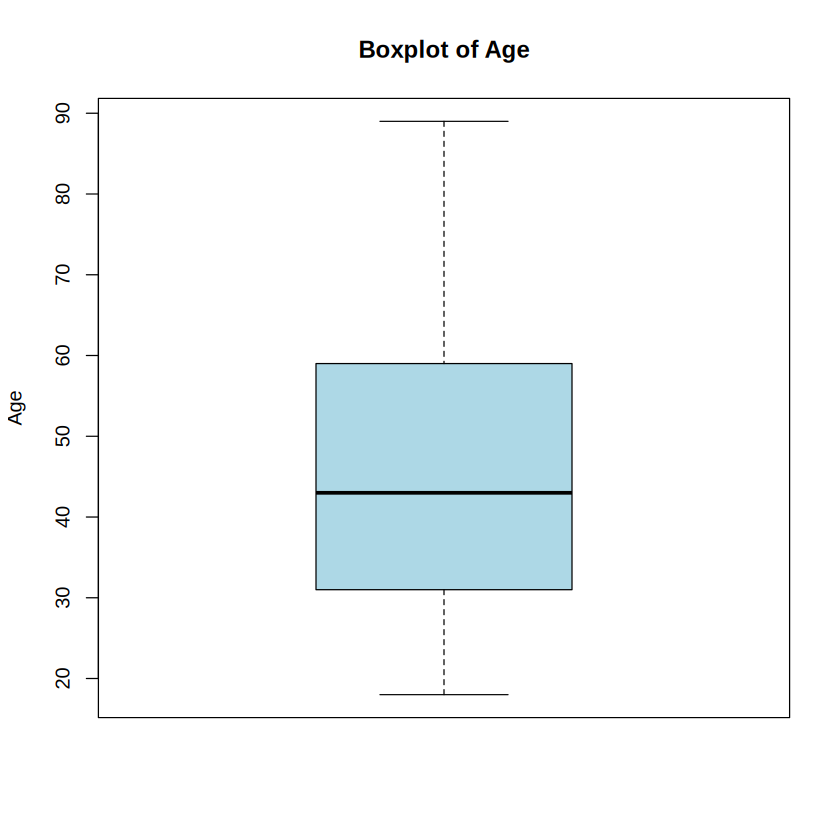

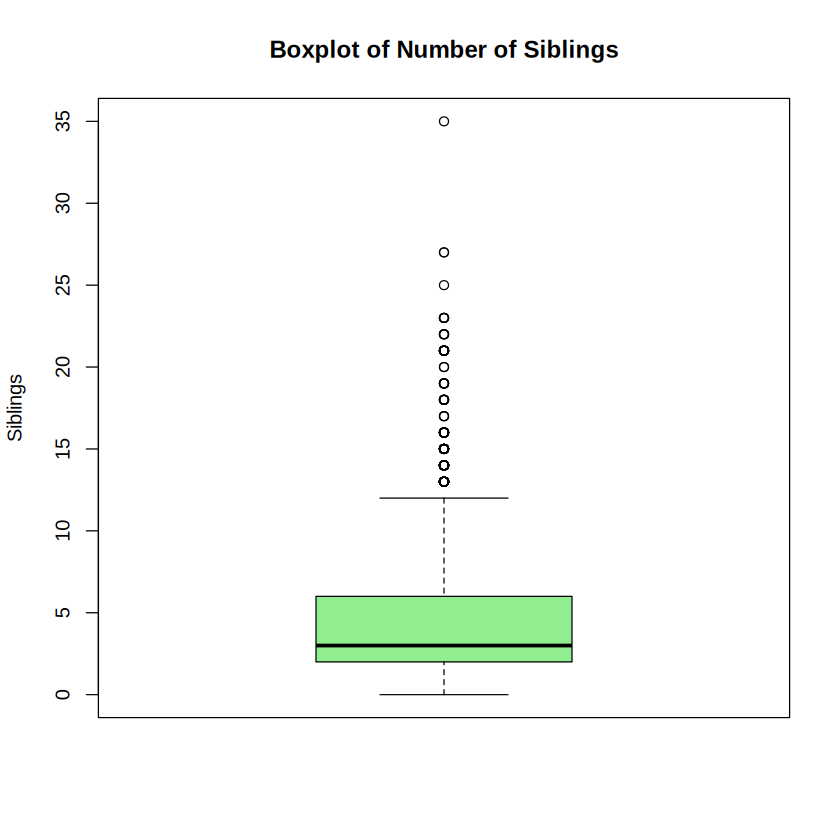

In [57]:
boxplot(df_clean$age,
        main = "Boxplot of Age",
        ylab = "Age",
        col = "lightblue")

boxplot(df_clean$siblings,
        main = "Boxplot of Number of Siblings",
        ylab = "Siblings",
        col = "lightgreen")

**Q15.** Identify outliers using the IQR method.

In [58]:
Q1 <- quantile(df_clean$siblings, 0.25)
Q3 <- quantile(df_clean$siblings, 0.75)
IQR_val <- IQR(df_clean$siblings)

lower_bound <- Q1 - 1.5 * IQR_val
upper_bound <- Q3 + 1.5 * IQR_val

cat("Lower bound:", lower_bound, " Upper bound:", upper_bound, "\n")

outliers_siblings <- df_clean %>%
  filter(siblings < lower_bound | siblings > upper_bound)

nrow(outliers_siblings)
head(outliers_siblings)

Lower bound: -4  Upper bound: 12 


[1] 194

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant,ethnicity_upper,city16_lower
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<chr>,<chr>
18,1,52,14,2002,21,20,other,no,yes,no,OTHER,no
148,8,68,5,2002,15,15,cauc,yes,no,no,CAUC,yes
149,0,35,13,2002,15,22,other,yes,no,no,OTHER,yes
155,2,25,11,2002,15,17,other,no,yes,no,OTHER,no
198,3,52,5,2002,15,22,other,yes,no,yes,OTHER,yes
228,2,40,14,2002,17,27,other,yes,no,yes,OTHER,yes


**Q16.** Remove extreme outliers.

In [59]:
df_no_outliers <- df_clean %>%
  filter(siblings >= lower_bound & siblings <= upper_bound)

dim(df_clean)
dim(df_no_outliers)

df_clean <- df_no_outliers

[1] 9120   13

[1] 8926   13

**Q17.** Histogram of a numerical variable.

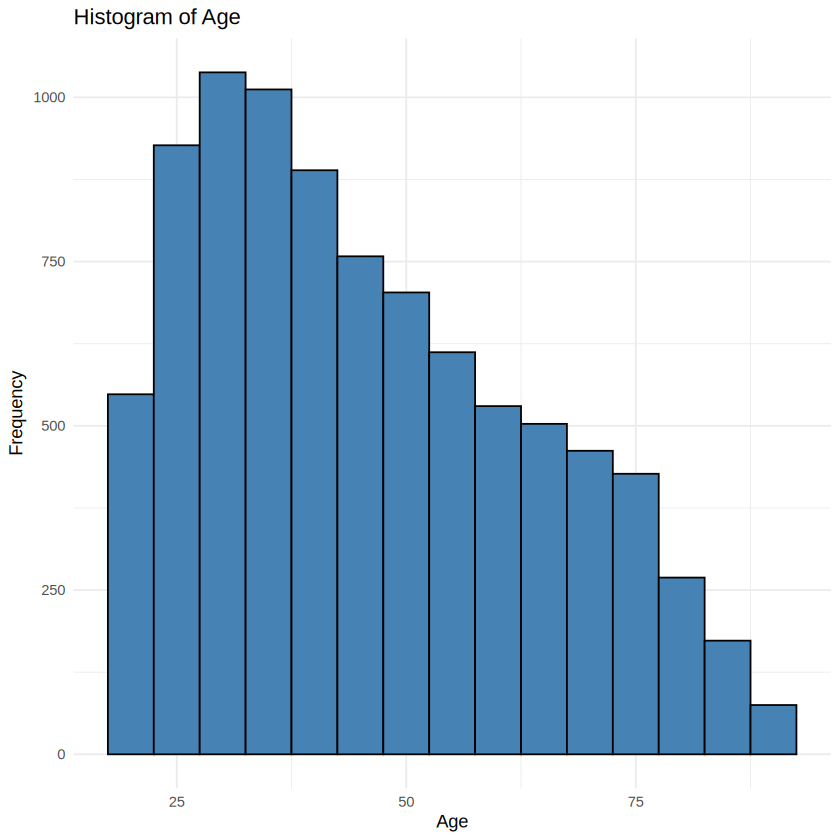

In [60]:
ggplot(df_clean, aes(x = age)) +
  geom_histogram(binwidth = 5, fill = "steelblue", color = "black") +
  labs(title = "Histogram of Age", x = "Age", y = "Frequency") +
  theme_minimal()

**Q18.** Add a density curve to the histogram.

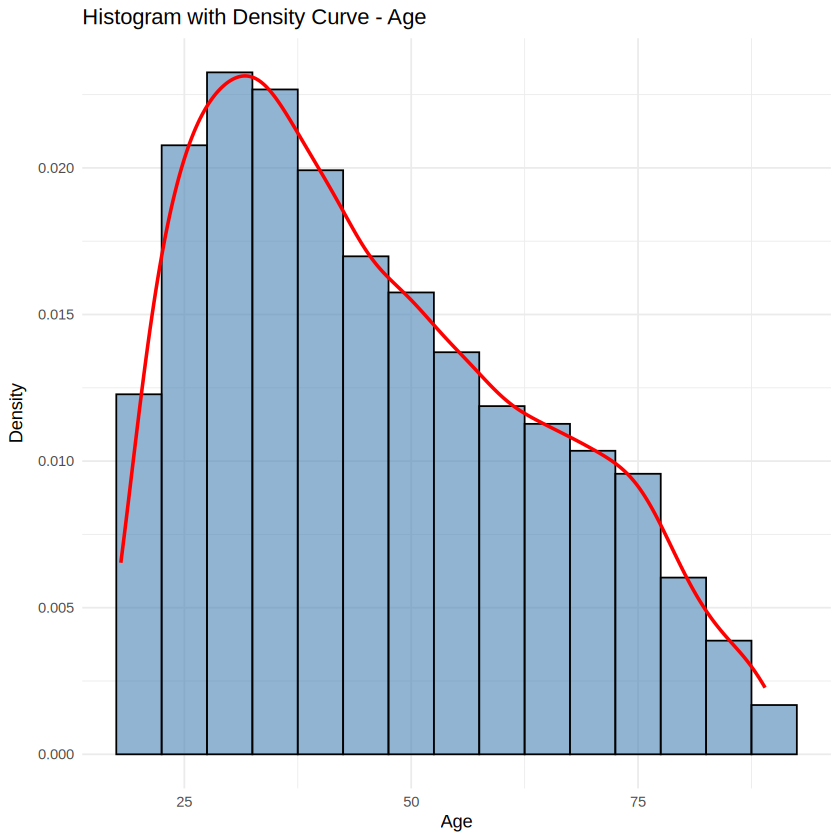

In [61]:
ggplot(df_clean, aes(x = age)) +
  geom_histogram(aes(y = after_stat(density)), binwidth = 5,
                 fill = "steelblue", color = "black", alpha = 0.6) +
  geom_density(color = "red", linewidth = 1) +
  labs(title = "Histogram with Density Curve - Age", x = "Age", y = "Density") +
  theme_minimal()

**Q19.** Violin plot.

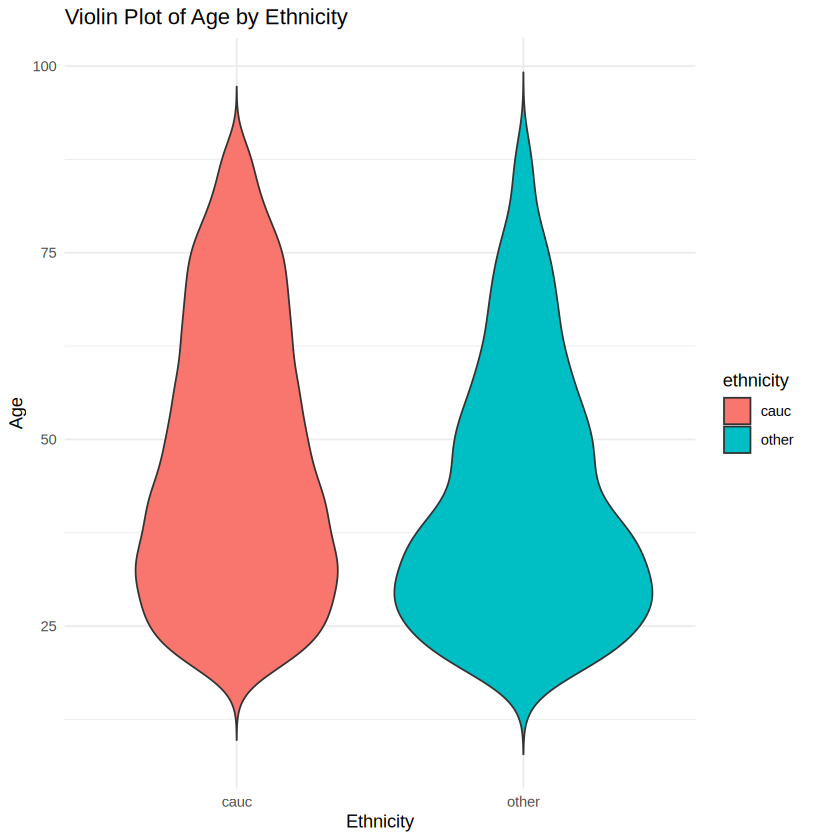

In [62]:
ggplot(df_clean, aes(x = ethnicity, y = age, fill = ethnicity)) +
  geom_violin(trim = FALSE) +
  labs(title = "Violin Plot of Age by Ethnicity", x = "Ethnicity", y = "Age") +
  theme_minimal()

**Q20.** Dot plot for a small numerical sample.

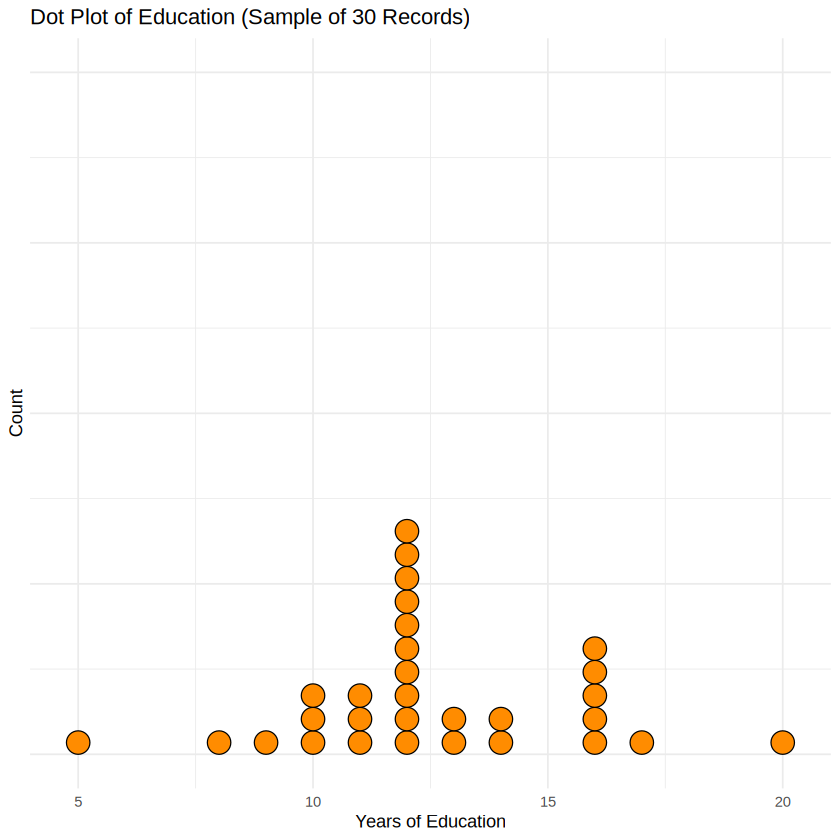

In [63]:
small_sample <- df_clean %>% slice_sample(n = 30)

ggplot(small_sample, aes(x = education)) +
  geom_dotplot(binwidth = 0.5, fill = "darkorange") +
  labs(title = "Dot Plot of Education (Sample of 30 Records)",
       x = "Years of Education", y = "Count") +
  theme_minimal() +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())

**Q21.** Frequency table for a categorical variable.

In [64]:
freq_table <- table(df_clean$ethnicity)
freq_table


 cauc other 
 7234  1692 

**Q22.** Proportion and percentage of each category.

In [65]:
prop_table <- prop.table(freq_table)
percent_table <- prop_table * 100

data.frame(
  Category = names(freq_table),
  Frequency = as.vector(freq_table),
  Proportion = round(as.vector(prop_table), 4),
  Percentage = round(as.vector(percent_table), 2)
)

Category,Frequency,Proportion,Percentage
<chr>,<int>,<dbl>,<dbl>
cauc,7234,0.8104,81.04
other,1692,0.1896,18.96


**Q23.** Bar chart of frequencies.

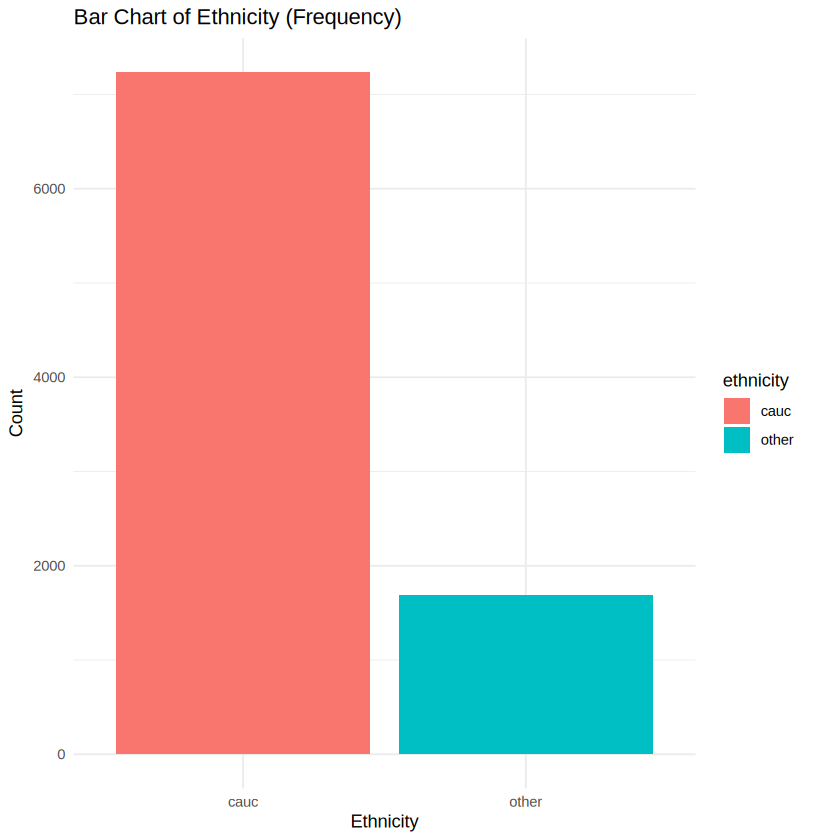

In [66]:
ggplot(df_clean, aes(x = ethnicity, fill = ethnicity)) +
  geom_bar() +
  labs(title = "Bar Chart of Ethnicity (Frequency)", x = "Ethnicity", y = "Count") +
  theme_minimal()

**Q24.** Horizontal bar chart.

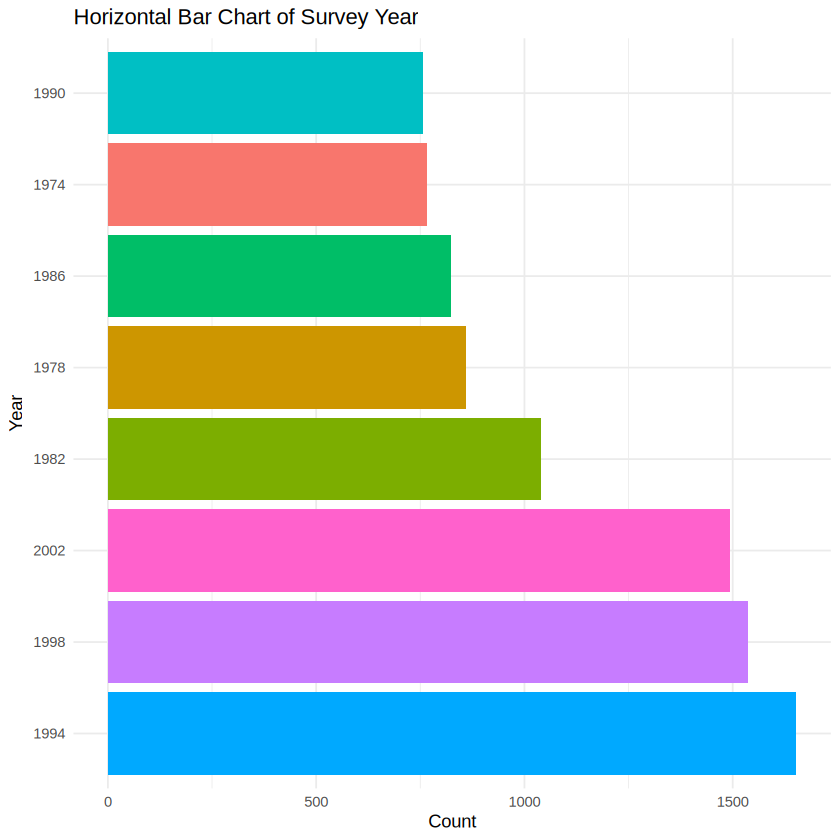

In [67]:
ggplot(df_clean, aes(x = fct_infreq(as.factor(year)), fill = as.factor(year))) +
  geom_bar() +
  coord_flip() +
  labs(title = "Horizontal Bar Chart of Survey Year", x = "Year", y = "Count") +
  theme_minimal() +
  theme(legend.position = "none")

**Q25.** Percentage bar chart.

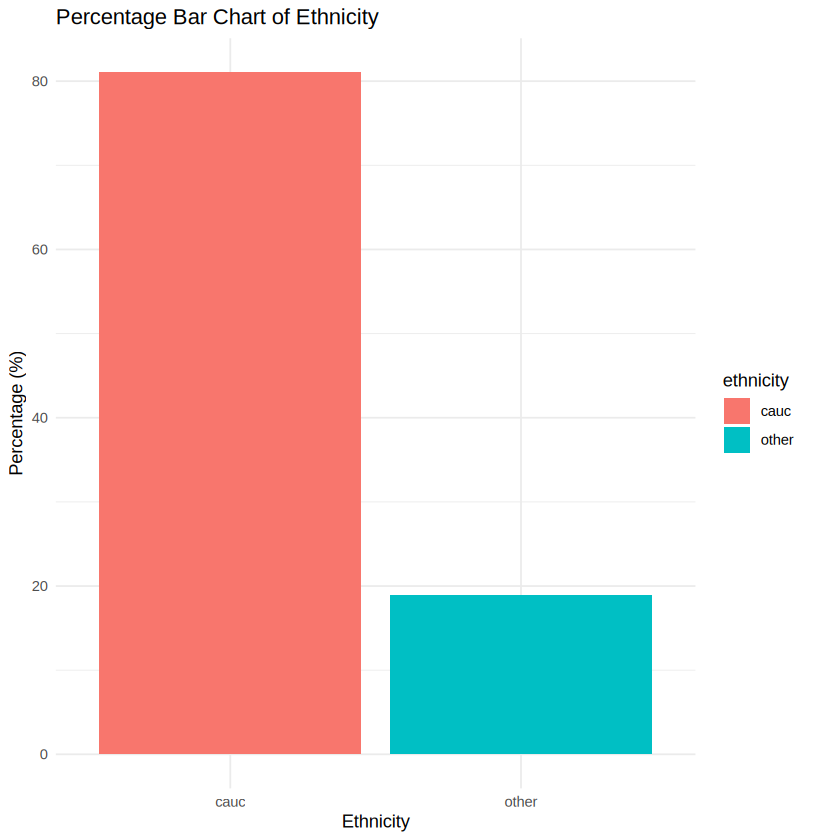

In [68]:
ggplot(df_clean, aes(x = ethnicity, y = after_stat(count) / sum(after_stat(count)) * 100,
                     fill = ethnicity)) +
  geom_bar() +
  labs(title = "Percentage Bar Chart of Ethnicity", x = "Ethnicity", y = "Percentage (%)") +
  theme_minimal()

**Q26.** Pie chart.

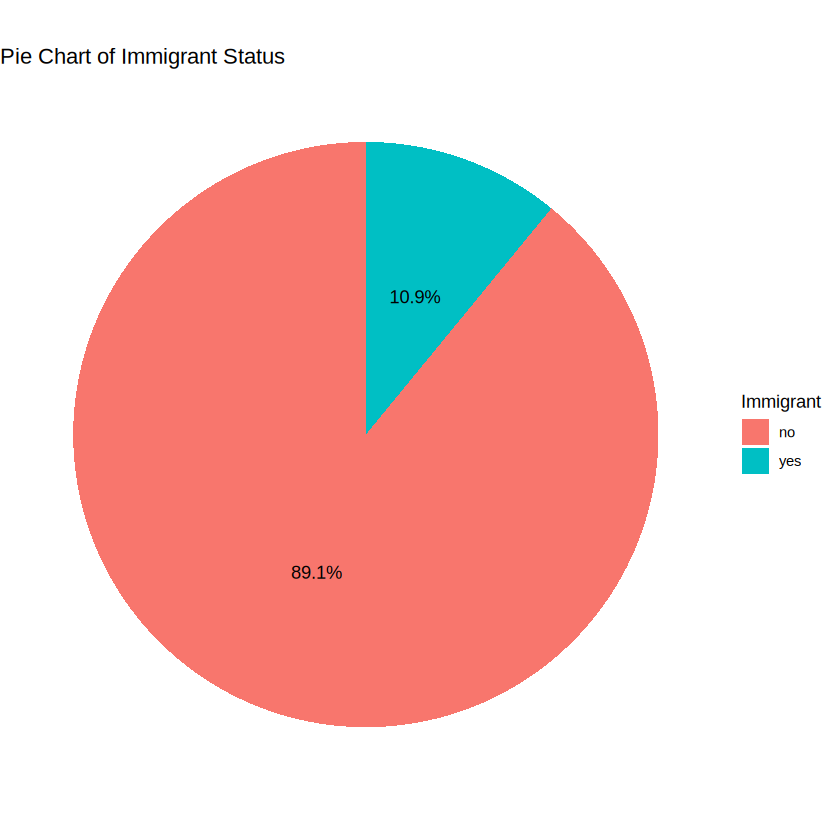

In [69]:
pie_data <- df_clean %>%
  count(immigrant) %>%
  mutate(percentage = round(n / sum(n) * 100, 1))

ggplot(pie_data, aes(x = "", y = n, fill = immigrant)) +
  geom_bar(stat = "identity", width = 1) +
  coord_polar(theta = "y") +
  labs(title = "Pie Chart of Immigrant Status", fill = "Immigrant") +
  geom_text(aes(label = paste0(percentage, "%")),
            position = position_stack(vjust = 0.5)) +
  theme_void()

**Q27.** Lollipop chart.

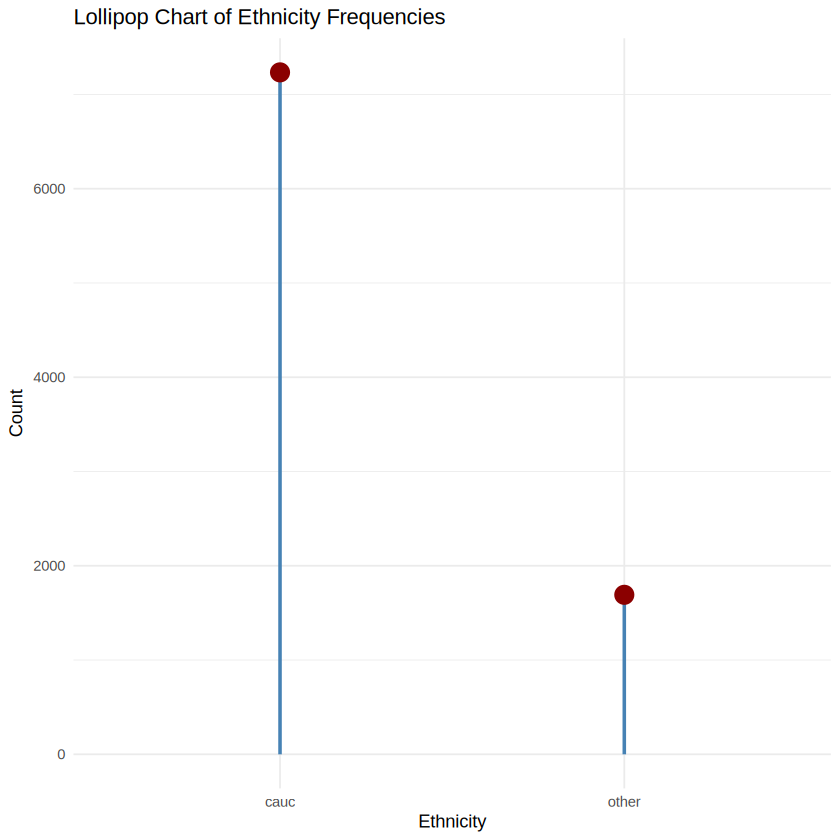

In [70]:
lollipop_data <- df_clean %>% count(ethnicity)

ggplot(lollipop_data, aes(x = ethnicity, y = n)) +
  geom_segment(aes(x = ethnicity, xend = ethnicity, y = 0, yend = n),
               color = "steelblue", linewidth = 1) +
  geom_point(size = 5, color = "darkred") +
  labs(title = "Lollipop Chart of Ethnicity Frequencies", x = "Ethnicity", y = "Count") +
  theme_minimal()

**Q28.** Dot chart.

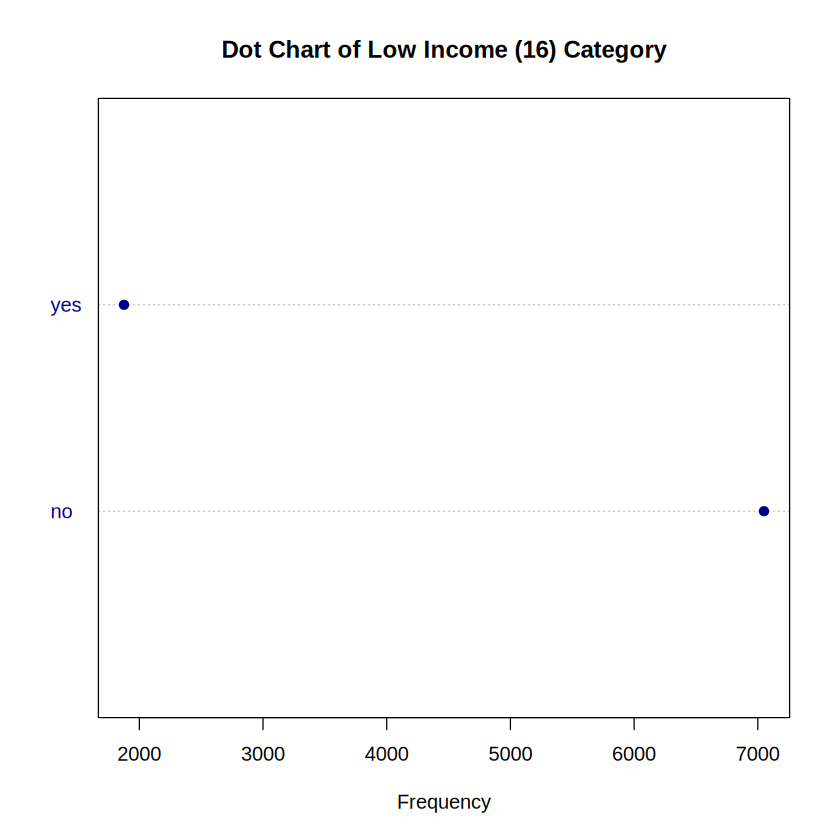

In [71]:
dotchart(as.numeric(table(df_clean$lowincome16)),
         labels = names(table(df_clean$lowincome16)),
         main = "Dot Chart of Low Income (16) Category",
         xlab = "Frequency",
         pch = 19, col = "darkblue")

**Q29.** Density plot using ggplot2.

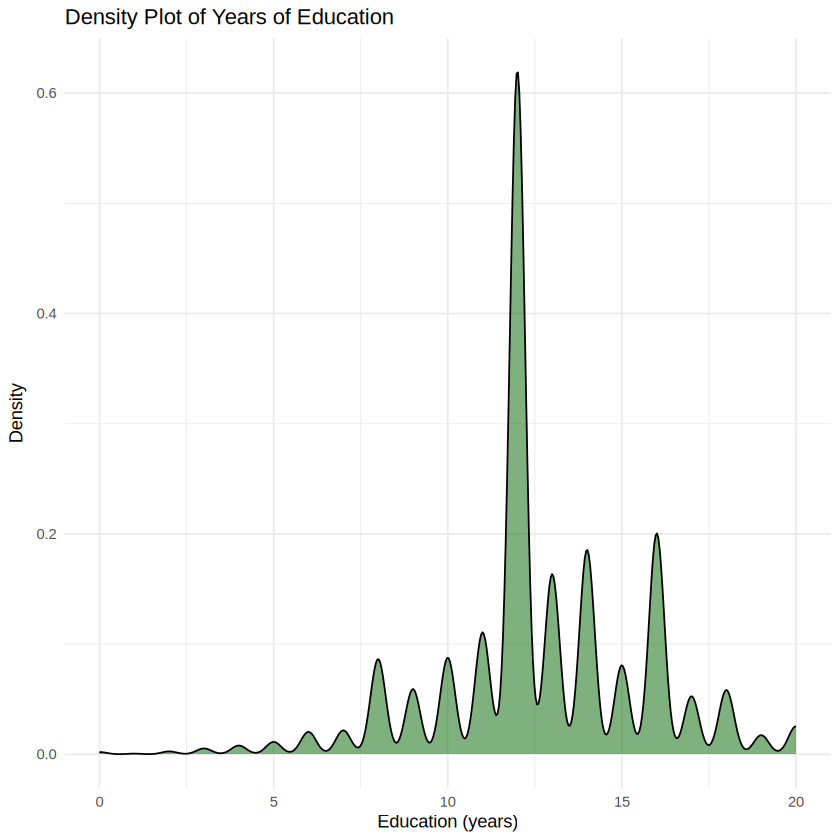

In [72]:
ggplot(df_clean, aes(x = education)) +
  geom_density(fill = "darkgreen", alpha = 0.5) +
  labs(title = "Density Plot of Years of Education", x = "Education (years)", y = "Density") +
  theme_minimal()

**Q30.** `facet_wrap()` — distribution of one variable across groups.

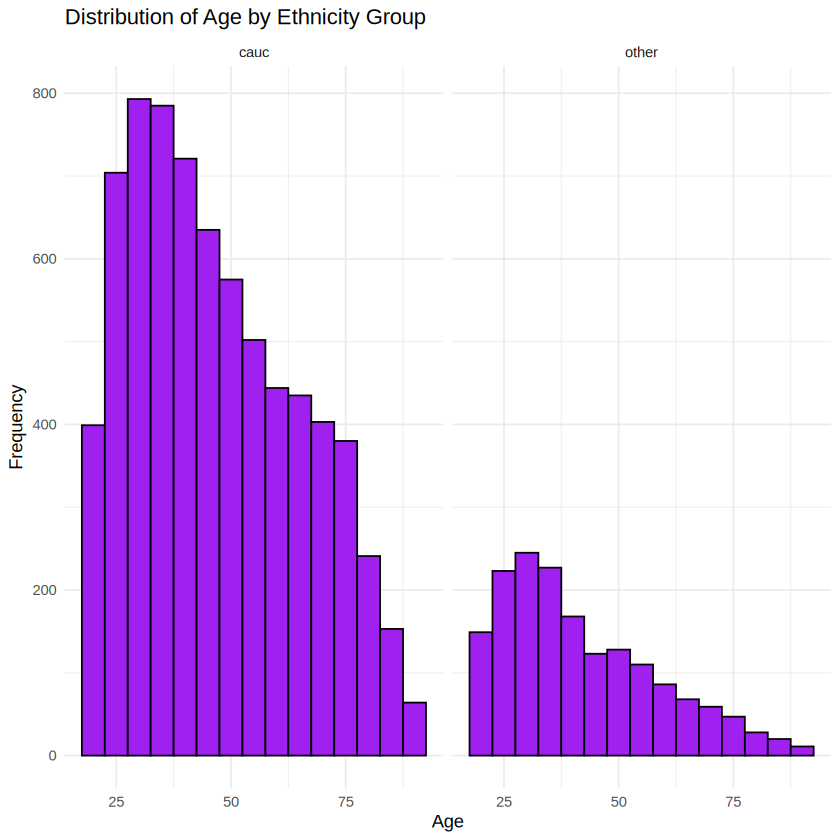

In [73]:
ggplot(df_clean, aes(x = age)) +
  geom_histogram(binwidth = 5, fill = "purple", color = "black") +
  facet_wrap(~ ethnicity) +
  labs(title = "Distribution of Age by Ethnicity Group", x = "Age", y = "Frequency") +
  theme_minimal()

---
# ASSESSMENT V — Multivariate Analysis
*Multivariate Data Visualization on the GSS7402 Dataset — Adharsh, 23BDS0029*

**Importing required packages**

In [74]:
required_packages <- c("readxl", "ggplot2", "dplyr", "GGally")

for (pkg in required_packages) {
  if (!require(pkg, character.only = TRUE)) {
    install.packages(pkg, dependencies = TRUE)
    library(pkg, character.only = TRUE)
  }
}

**Q1.** Load the dataset; identify numerical and categorical variables.

In [75]:
file_path <- data_path

gss <- read_excel(file_path)
gss <- as.data.frame(gss)

cat("\n===== Dataset dimensions =====\n")
print(dim(gss))

cat("\n===== Structure of the dataset =====\n")
str(gss)

cat("\n===== First few rows =====\n")
print(head(gss))

cat("\n===== Summary statistics =====\n")
print(summary(gss))

gss <- gss %>%
  mutate(across(where(is.character), as.factor))
numerical_vars <- names(gss)[sapply(gss, is.numeric)]
categorical_vars <- names(gss)[sapply(gss, is.factor)]

cat("\n===== Numerical variables =====\n")
print(numerical_vars)

cat("\n===== Categorical variables =====\n")
print(categorical_vars)
gss_afb <- gss %>% filter(!is.na(agefirstbirth))


===== Dataset dimensions =====
[1] 9120   11

===== Structure of the dataset =====
'data.frame':	9120 obs. of  11 variables:
 $ rownames     : num  1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num  0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num  25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num  14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num  2002 2002 2002 2002 2002 ...
 $ siblings     : num  1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num  NA 19 27 22 29 NA NA NA 21 20 ...
 $ ethnicity    : chr  "cauc" "cauc" "cauc" "cauc" ...
 $ city16       : chr  "no" "yes" "no" "no" ...
 $ lowincome16  : chr  "no" "no" "no" "no" ...
 $ immigrant    : chr  "no" "no" "yes" "no" ...

===== First few rows =====
  rownames kids age education year siblings agefirstbirth ethnicity city16
1        1    0  25        14 2002        1            NA      cauc     no
2        2    1  30        13 2002        4            19      cauc    yes
3        3    1  55         2 2002        1            27  

**Q2.** Scatter plot with three variables (x, y, colour).

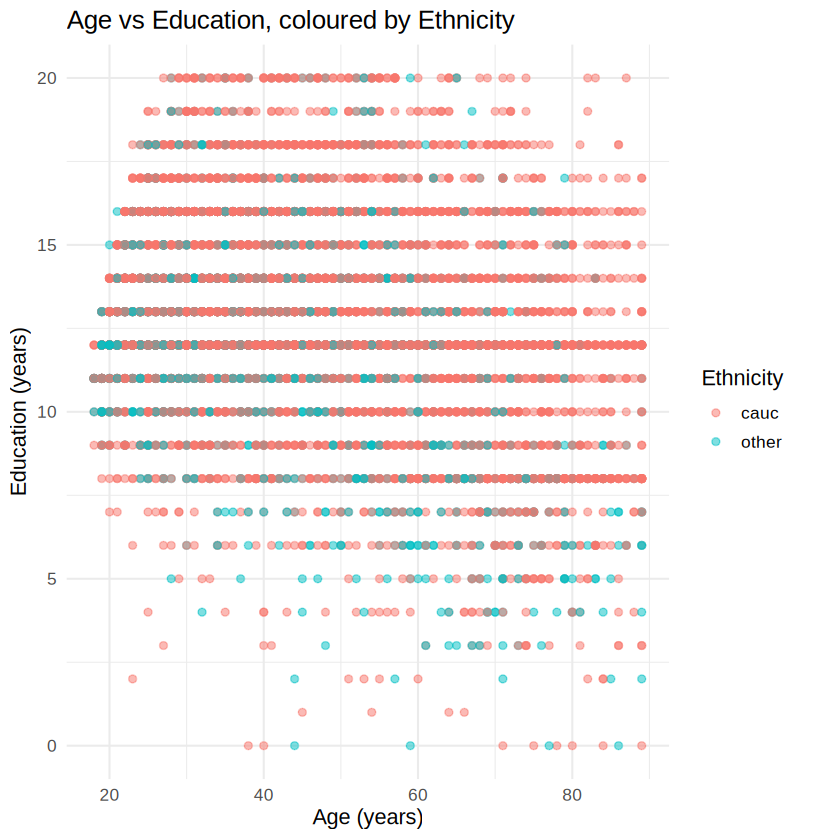

In [76]:
plot2 <- ggplot(gss, aes(x = age, y = education, color = ethnicity)) +
  geom_point(alpha = 0.5, size = 1.8) +
  labs(
    title = "Age vs Education, coloured by Ethnicity",
    x = "Age (years)",
    y = "Education (years)",
    color = "Ethnicity"
  ) +
  theme_minimal(base_size = 13)
print(plot2)

**Q3.** Scatter plot with four variables (x, y, colour, shape).

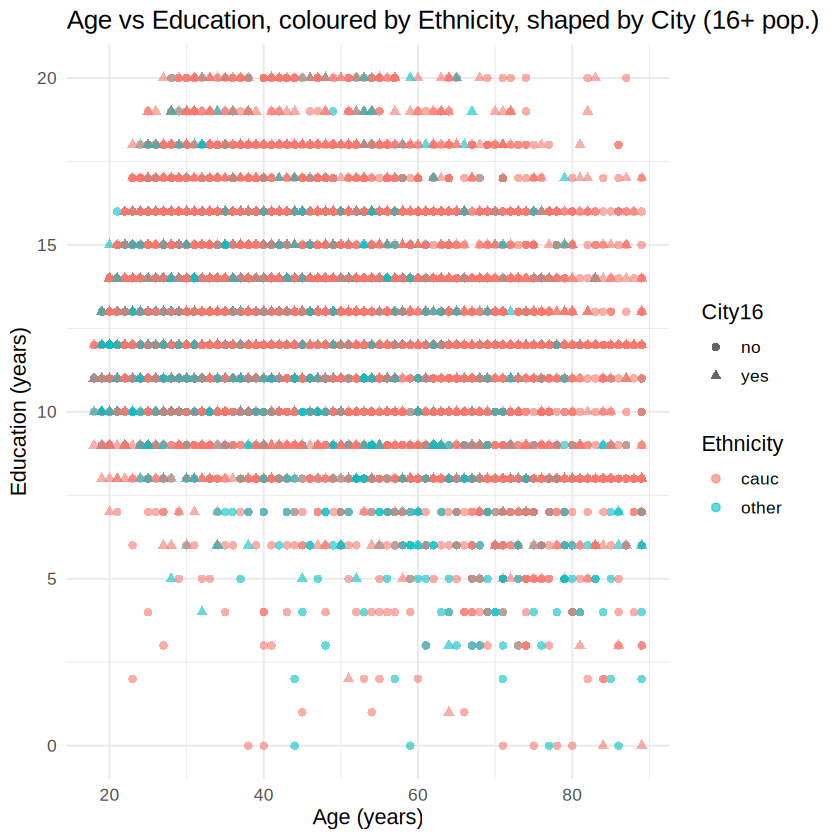

In [77]:
plot3 <- ggplot(gss, aes(x = age, y = education,
                         color = ethnicity, shape = city16)) +
  geom_point(alpha = 0.6, size = 2) +
  labs(
    title = "Age vs Education, coloured by Ethnicity, shaped by City (16+ pop.)",
    x = "Age (years)",
    y = "Education (years)",
    color = "Ethnicity",
    shape = "City16"
  ) +
  theme_minimal(base_size = 13)
print(plot3)

**Q4.** Scatter plot with four variables (x, y, colour, size).

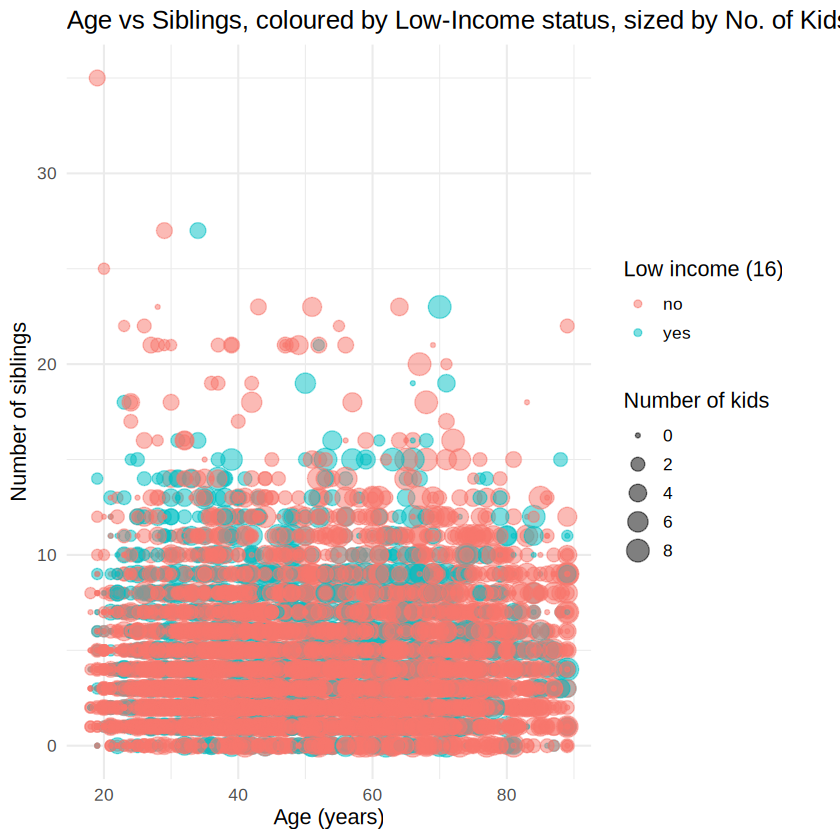

In [78]:
plot4 <- ggplot(gss, aes(x = age, y = siblings,
                         color = lowincome16, size = kids)) +
  geom_point(alpha = 0.5) +
  labs(
    title = "Age vs Siblings, coloured by Low-Income status, sized by No. of Kids",
    x = "Age (years)",
    y = "Number of siblings",
    color = "Low income (16)",
    size = "Number of kids"
  ) +
  theme_minimal(base_size = 13)

print(plot4)

**Q5.** Bubble plot using three numerical variables.

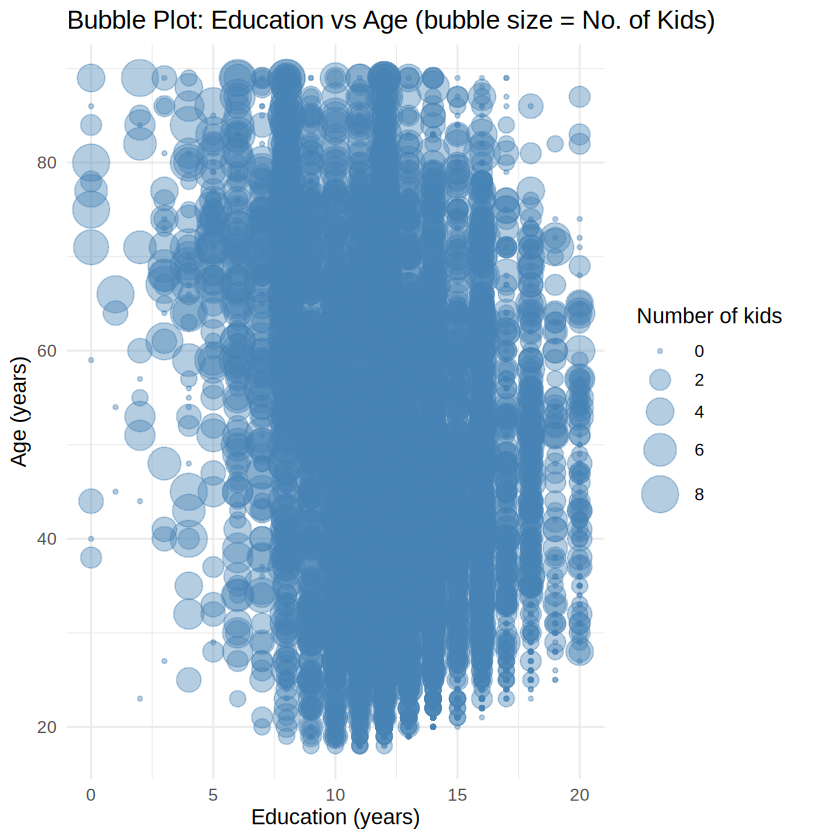

In [79]:
plot5 <- ggplot(gss, aes(x = education, y = age, size = kids)) +
  geom_point(alpha = 0.4, color = "steelblue") +
  scale_size(range = c(1, 10)) +
  labs(
    title = "Bubble Plot: Education vs Age (bubble size = No. of Kids)",
    x = "Education (years)",
    y = "Age (years)",
    size = "Number of kids"
  ) +
  theme_minimal(base_size = 13)
print(plot5)

**Q6.** Subplots using `facet_wrap()`.

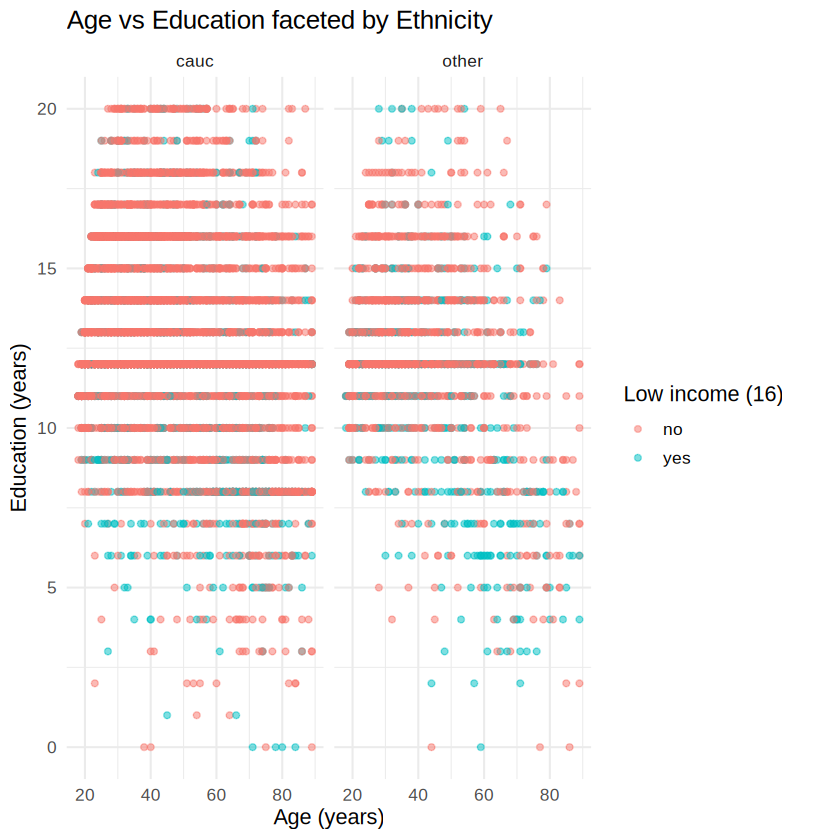

In [80]:
plot6 <- ggplot(gss, aes(x = age, y = education, color = lowincome16)) +
  geom_point(alpha = 0.5, size = 1.5) +
  facet_wrap(~ ethnicity) +
  labs(
    title = "Age vs Education faceted by Ethnicity",
    x = "Age (years)",
    y = "Education (years)",
    color = "Low income (16)"
  ) +
  theme_minimal(base_size = 13)
print(plot6)

**Q7.** Subplots using `facet_grid()`.

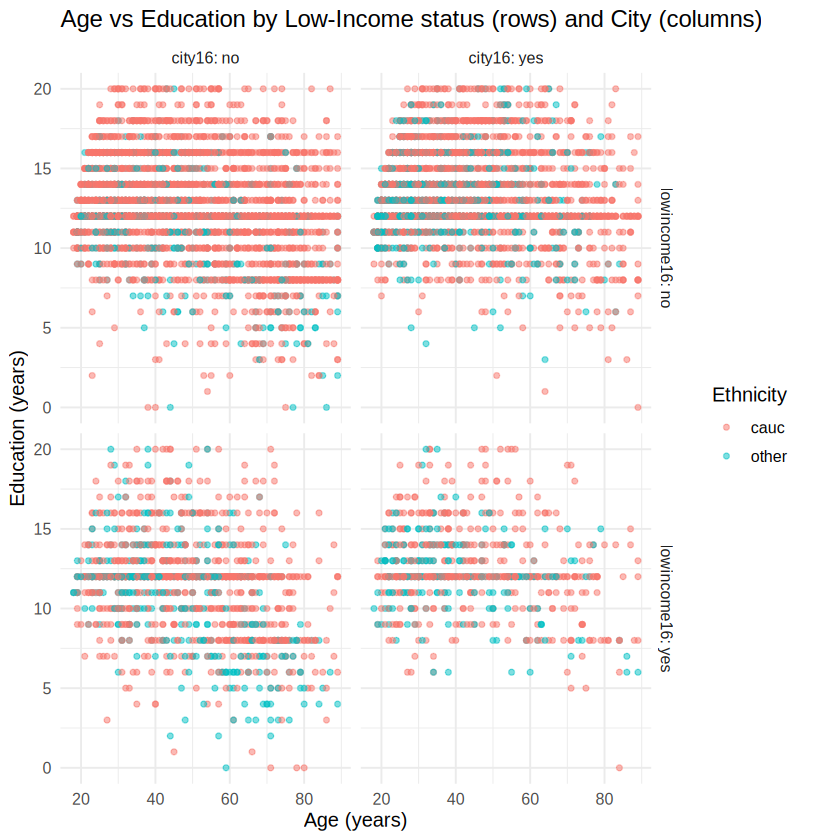

In [81]:
plot7 <- ggplot(gss, aes(x = age, y = education, color = ethnicity)) +
  geom_point(alpha = 0.5, size = 1.3) +
  facet_grid(lowincome16 ~ city16,
             labeller = label_both) +
  labs(
    title = "Age vs Education by Low-Income status (rows) and City (columns)",
    x = "Age (years)",
    y = "Education (years)",
    color = "Ethnicity"
  ) +
  theme_minimal(base_size = 12)
print(plot7)

**Q8.** Pairs plot using at least four numerical variables.

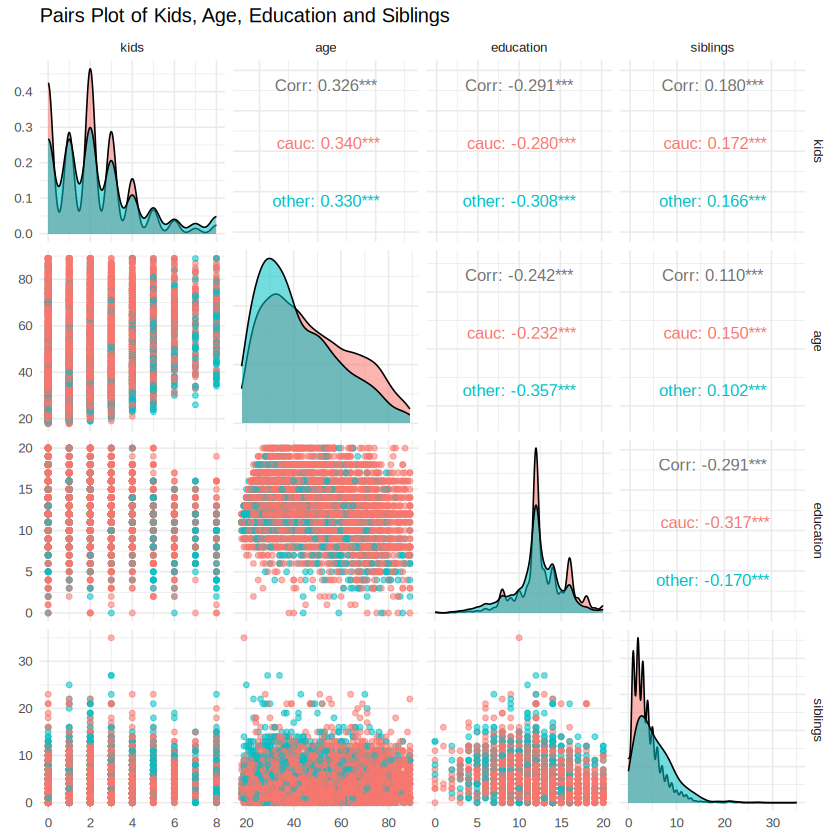

In [82]:
pairs_vars <- c("kids", "age", "education", "siblings")

plot8 <- ggpairs(
  gss,
  columns = pairs_vars,
  aes(color = ethnicity, alpha = 0.5),
  title = "Pairs Plot of Kids, Age, Education and Siblings"
) +
  theme_minimal(base_size = 10)
print(plot8)

**Q9.** Parallel coordinate plot.

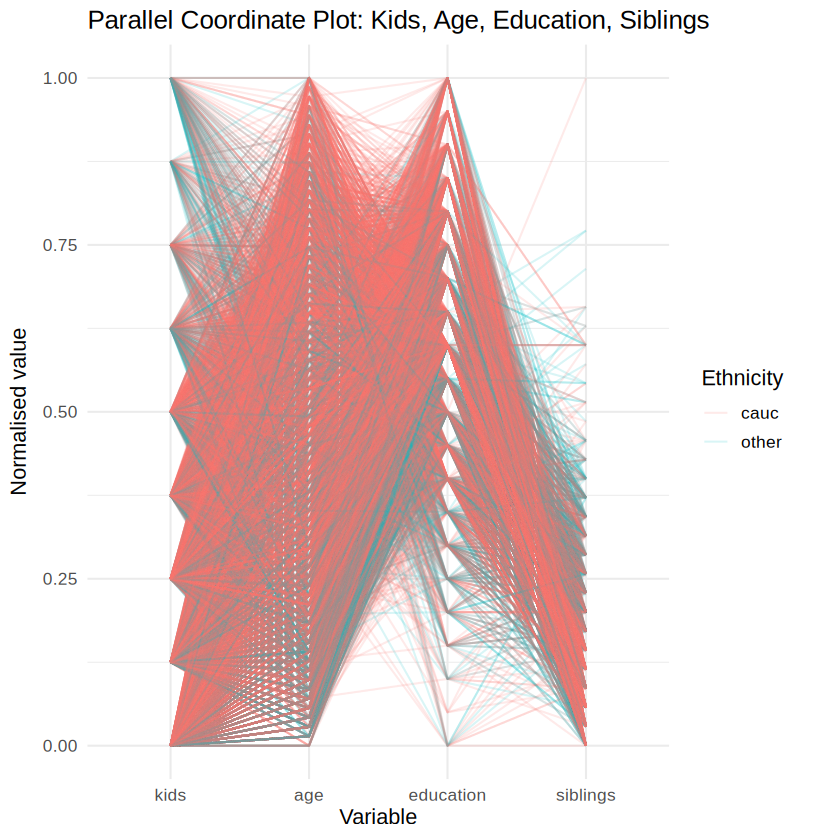

In [83]:
parcoord_vars <- c("kids", "age", "education", "siblings")

plot9 <- ggparcoord(
  data = gss,
  columns = which(names(gss) %in% parcoord_vars),
  groupColumn = "ethnicity",
  scale = "uniminmax",
  alphaLines = 0.15
) +
  labs(
    title = "Parallel Coordinate Plot: Kids, Age, Education, Siblings",
    x = "Variable",
    y = "Normalised value",
    color = "Ethnicity"
  ) +
  theme_minimal(base_size = 13)
print(plot9)

---
# ASSESSMENT VI — Time Series Analysis
Dataset: built-in `AirPassengers`.

In [84]:
library(forecast)

**Q1.** Load the built-in AirPassengers dataset.

In [85]:
data("AirPassengers")
ap <- AirPassengers

**Q2.** First five and last five observations.

In [86]:
cat("First five observations:\n")
print(head(ap, 5))

cat("\nLast five observations:\n")
print(tail(ap, 5))

First five observations:
     Jan Feb Mar Apr May
1949 112 118 132 129 121

Last five observations:
     Aug Sep Oct Nov Dec
1960 606 508 461 390 432


**Q3.** Starting and ending time periods.

In [87]:
start_period <- start(ap)
end_period <- end(ap)

cat("\nStart period:", start_period, "\n")
cat("End period:", end_period, "\n")


Start period: 1949 1 
End period: 1960 12 


**Q4.** Frequency and time-series characteristics.

In [88]:
ts_frequency <- frequency(ap)
ts_class <- class(ap)
cat("\nFrequency:", ts_frequency, "\n")
cat("Class:", ts_class, "\n")
cat("\nSummary of the series:\n")
print(summary(ap))


Frequency: 12 
Class: ts 

Summary of the series:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  104.0   180.0   265.5   280.3   360.5   622.0 


**Q5.** Visualize the monthly passenger trend.

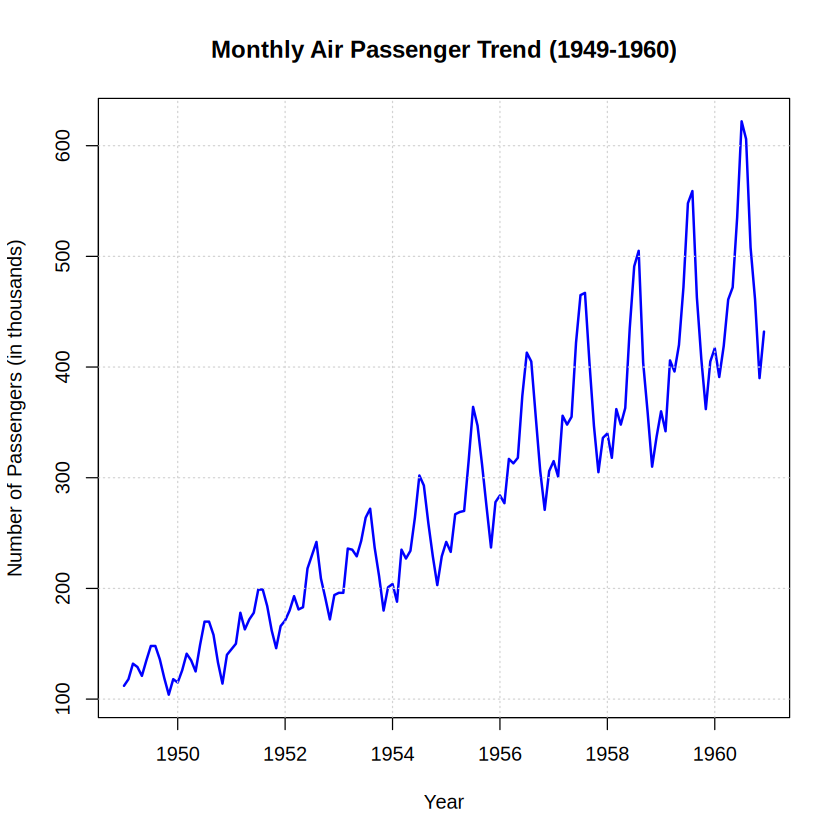

In [89]:
plot(ap,
     main = "Monthly Air Passenger Trend (1949-1960)",
     xlab = "Year",
     ylab = "Number of Passengers (in thousands)",
     col = "blue",
     lwd = 2)
grid()

**Q6.** Decompose into trend, seasonal and random components.

In [90]:
decomposed_ap <- decompose(ap, type = "multiplicative")
print(decomposed_ap)

$x
     Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec
1949 112 118 132 129 121 135 148 148 136 119 104 118
1950 115 126 141 135 125 149 170 170 158 133 114 140
1951 145 150 178 163 172 178 199 199 184 162 146 166
1952 171 180 193 181 183 218 230 242 209 191 172 194
1953 196 196 236 235 229 243 264 272 237 211 180 201
1954 204 188 235 227 234 264 302 293 259 229 203 229
1955 242 233 267 269 270 315 364 347 312 274 237 278
1956 284 277 317 313 318 374 413 405 355 306 271 306
1957 315 301 356 348 355 422 465 467 404 347 305 336
1958 340 318 362 348 363 435 491 505 404 359 310 337
1959 360 342 406 396 420 472 548 559 463 407 362 405
1960 417 391 419 461 472 535 622 606 508 461 390 432

$seasonal
           Jan       Feb       Mar       Apr       May       Jun       Jul
1949 0.9102304 0.8836253 1.0073663 0.9759060 0.9813780 1.1127758 1.2265555
1950 0.9102304 0.8836253 1.0073663 0.9759060 0.9813780 1.1127758 1.2265555
1951 0.9102304 0.8836253 1.0073663 0.9759060 0.9813780 1.1127758 1.22655

**Q7.** Plot the decomposed components.

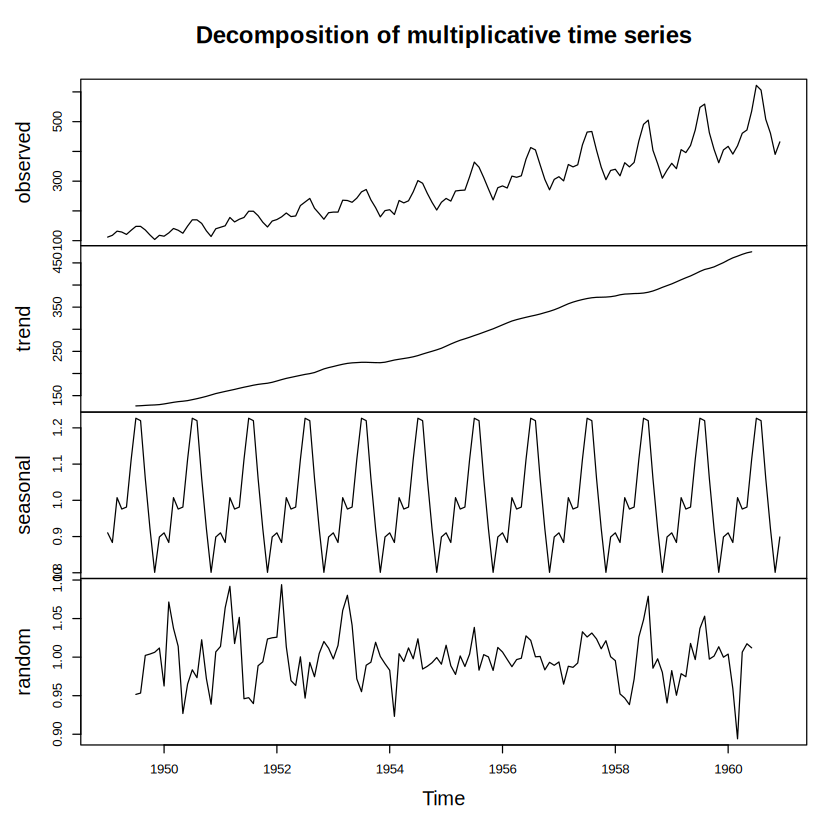

In [91]:
plot(decomposed_ap)

**Q8.** ACF and PACF.

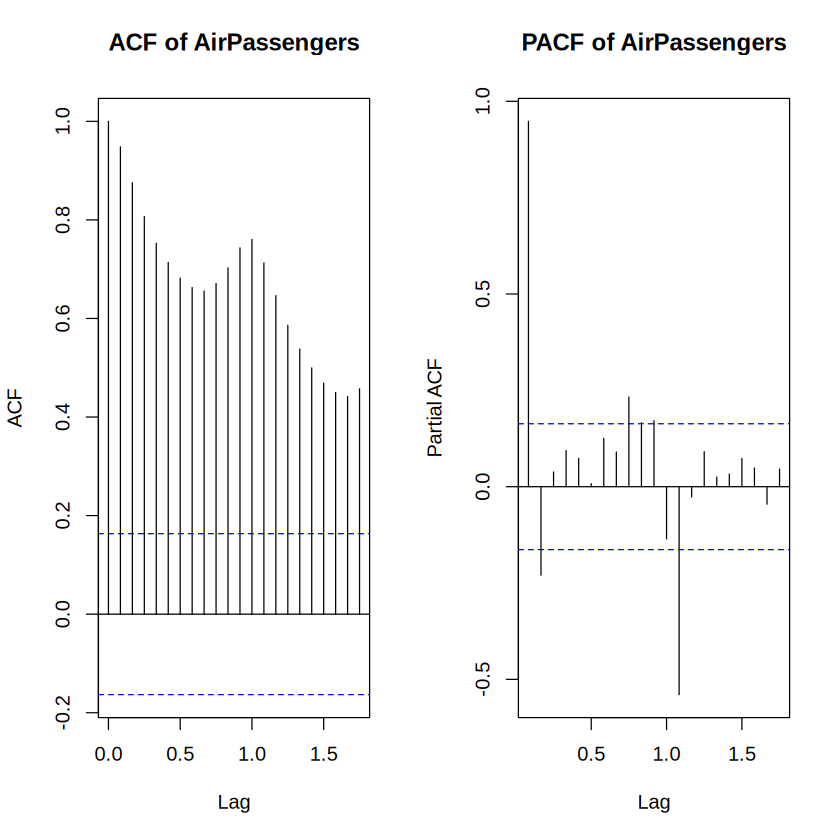

In [92]:
par(mfrow = c(1, 2))
acf(ap, main = "ACF of AirPassengers")
pacf(ap, main = "PACF of AirPassengers")
par(mfrow = c(1, 1))

**Q9.** Fit an ARIMA model.

In [93]:
arima_model <- auto.arima(ap)

**Q10.** Display and interpret the fitted ARIMA model.

In [94]:
cat("\nFitted ARIMA Model Summary:\n")
print(summary(arima_model))
cat("\nModel coefficients:\n")
print(arima_model$coef)
cat("\nInterpretation:\n")
cat("The auto.arima() function selected an ARIMA",
    paste0("(", arima_model$arma[1], ",", arima_model$arma[6], ",", arima_model$arma[2], ")"),
    "seasonal",
    paste0("(", arima_model$arma[3], ",", arima_model$arma[7], ",", arima_model$arma[4], ")"),
    "model with a seasonal period of", arima_model$arma[5], "months.\n")
cat("AIC:", arima_model$aic, " | BIC:", arima_model$bic, " | Log-likelihood:", arima_model$loglik, "\n")


Fitted ARIMA Model Summary:
Series: ap 
ARIMA(2,1,1)(0,1,0)[12] 

Coefficients:
         ar1     ar2      ma1
      0.5960  0.2143  -0.9819
s.e.  0.0888  0.0880   0.0292

sigma^2 = 132.3:  log likelihood = -504.92
AIC=1017.85   AICc=1018.17   BIC=1029.35

Training set error measures:
                   ME     RMSE     MAE       MPE     MAPE     MASE         ACF1
Training set 1.342299 10.84619 7.86754 0.4206976 2.800458 0.245628 -0.001248475

Model coefficients:
       ar1        ar2        ma1 
 0.5959807  0.2142746 -0.9818772 

Interpretation:
The auto.arima() function selected an ARIMA (2,1,1) seasonal (0,1,0) model with a seasonal period of 12 months.
AIC: 1017.848  | BIC: 1029.348  | Log-likelihood: -504.9239 


**Q11.** Forecast the next 12 months.

In [95]:
forecast_values <- predict(arima_model, n.ahead = 12)
cat("\nForecasted values for the next 12 months:\n")
print(forecast_values$pred)
cat("\nStandard errors of the forecast:\n")
print(forecast_values$se)


Forecasted values for the next 12 months:
          Jan      Feb      Mar      Apr      May      Jun      Jul      Aug
1961 445.6349 420.3950 449.1983 491.8399 503.3945 566.8625 654.2602 638.5975
          Sep      Oct      Nov      Dec
1961 540.8837 494.1266 423.3327 465.5076

Standard errors of the forecast:
          Jan      Feb      Mar      Apr      May      Jun      Jul      Aug
1961 11.50524 13.50261 15.15799 16.24046 17.04072 17.63388 18.08602 18.43632
          Sep      Oct      Nov      Dec
1961 18.71242 18.93349 19.11323 19.26159


**Q12.** Actual vs forecasted values.

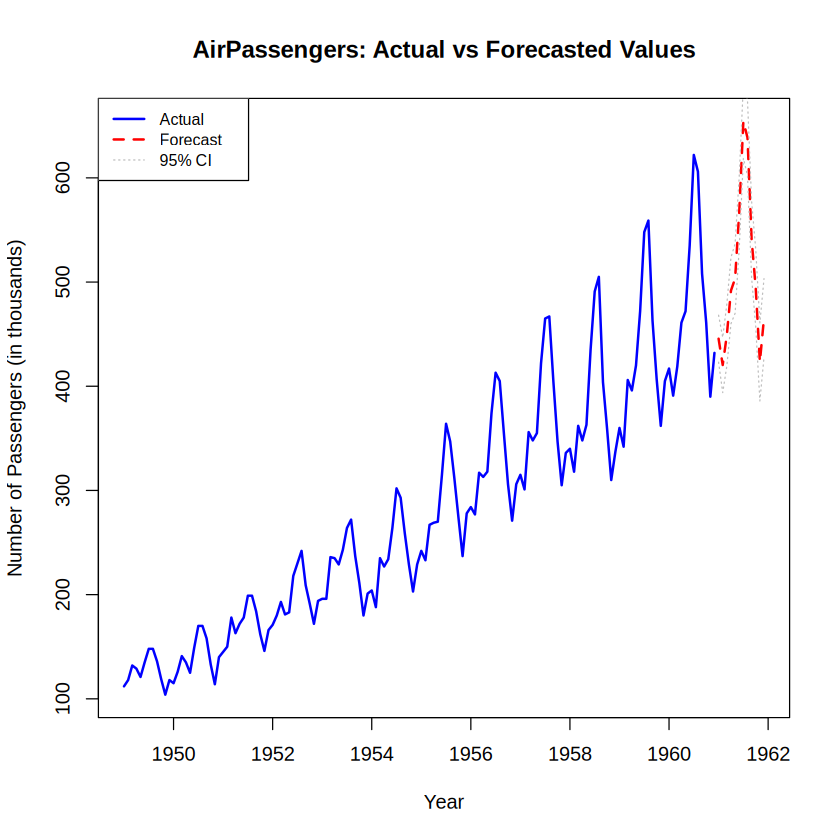

In [96]:
ts.plot(ap, forecast_values$pred,
        col = c("blue", "red"),
        lty = c(1, 2),
        lwd = 2,
        main = "AirPassengers: Actual vs Forecasted Values",
        xlab = "Year",
        ylab = "Number of Passengers (in thousands)")
lines(forecast_values$pred + 1.96 * forecast_values$se, col = "gray", lty = 3)
lines(forecast_values$pred - 1.96 * forecast_values$se, col = "gray", lty = 3)
legend("topleft",
       legend = c("Actual", "Forecast", "95% CI"),
       col = c("blue", "red", "gray"),
       lty = c(1, 2, 3),
       lwd = c(2, 2, 1),
       cex = 0.8)

---
# ASSESSMENT VII — 1D, 2D and ND Analysis

In [97]:
library(readxl)
library(e1071)
library(ggplot2)
library(dplyr)
library(corrplot)


Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element


corrplot 0.95 loaded



**Q1.** Load the dataset.

In [98]:
data <- read_excel(data_path)
head(data)
str(data)
dim(data)
names(data)
summary(data)

rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,0,25,14,2002,1,NA,cauc,no,no,no
2,1,30,13,2002,4,19,cauc,yes,no,no
3,1,55,2,2002,1,27,cauc,no,no,yes
4,2,57,16,2002,1,22,cauc,no,no,no
5,2,71,12,2002,6,29,cauc,yes,no,no
6,0,19,13,2002,1,NA,other,yes,no,no


tibble [9,120 × 11] (S3: tbl_df/tbl/data.frame)
 $ rownames     : num [1:9120] 1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num [1:9120] 0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num [1:9120] 25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num [1:9120] 14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num [1:9120] 2002 2002 2002 2002 2002 ...
 $ siblings     : num [1:9120] 1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num [1:9120] NA 19 27 22 29 NA NA NA 21 20 ...
 $ ethnicity    : chr [1:9120] "cauc" "cauc" "cauc" "cauc" ...
 $ city16       : chr [1:9120] "no" "yes" "no" "no" ...
 $ lowincome16  : chr [1:9120] "no" "no" "no" "no" ...
 $ immigrant    : chr [1:9120] "no" "no" "yes" "no" ...


[1] 9120   11

[1] "rownames"      "kids"          "age"           "education"    
 [5] "year"          "siblings"      "agefirstbirth" "ethnicity"    
 [9] "city16"        "lowincome16"   "immigrant"

    rownames         kids            age          education          year     
 Min.   :   1   Min.   :0.000   Min.   :18.00   Min.   : 0.00   Min.   :1974  
 1st Qu.:2281   1st Qu.:1.000   1st Qu.:31.00   1st Qu.:12.00   1st Qu.:1982  
 Median :4560   Median :2.000   Median :43.00   Median :12.00   Median :1994  
 Mean   :4560   Mean   :2.076   Mean   :46.08   Mean   :12.64   Mean   :1990  
 3rd Qu.:6840   3rd Qu.:3.000   3rd Qu.:59.00   3rd Qu.:14.00   3rd Qu.:1998  
 Max.   :9120   Max.   :8.000   Max.   :89.00   Max.   :20.00   Max.   :2002  
                                                                              
    siblings      agefirstbirth       ethnicity          city16    
 Min.   : 0.000   Min.   : 9.00   Length   :9120   Length   :9120  
 1st Qu.: 2.000   1st Qu.:19.00   N.unique :   2   N.unique :   2  
 Median : 3.000   Median :22.00   N.blank  :   0   N.blank  :   0  
 Mean   : 4.051   Mean   :22.63   Min.nchar:   4   Min.nchar:   2  
 3rd Qu.: 6.000   3rd Qu.:25

**Q2.** Missing values and duplicates check.

In [99]:
colSums(is.na(data))
sapply(data, function(x) sum(is.na(x)))
sum(duplicated(data))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808             0             0             0 
    immigrant 
            0

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808             0             0             0 
    immigrant 
            0

[1] 0

**Q3.** Summary statistics (Mean, Median, Min, Max, Range, Variance, SD, IQR, Skewness, Kurtosis) stored in a data frame.

In [100]:
x <- data$age
mean_age <- mean(x, na.rm = TRUE)
median_age <- median(x, na.rm = TRUE)
minimum_age <- min(x, na.rm = TRUE)
maximum_age <- max(x, na.rm = TRUE)
range_age <- maximum_age - minimum_age
variance_age <- var(x, na.rm = TRUE)
sd_age <- sd(x, na.rm = TRUE)
iqr_age <- IQR(x, na.rm = TRUE)
skewness_age <- e1071::skewness(x, na.rm = TRUE)
kurtosis_age <- e1071::kurtosis(x, na.rm = TRUE)
summary_statistics <- data.frame(
  Statistic = c(
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Range",
    "Variance",
    "Standard Deviation",
    "IQR",
    "Skewness",
    "Kurtosis"
  ),
  Value = c(
    mean_age,
    median_age,
    minimum_age,
    maximum_age,
    range_age,
    variance_age,
    sd_age,
    iqr_age,
    skewness_age,
    kurtosis_age
  )
)
print(summary_statistics)

            Statistic       Value
1                Mean  46.0820175
2              Median  43.0000000
3             Minimum  18.0000000
4             Maximum  89.0000000
5               Range  71.0000000
6            Variance 321.2657803
7  Standard Deviation  17.9238885
8                 IQR  28.0000000
9            Skewness   0.4764246
10           Kurtosis  -0.7809245


**Q4.** Frequency / relative frequency tables, pie chart and bar plot for a categorical variable.


 cauc other 
 7335  1785 

     cauc     other 
0.8042763 0.1957237 

    cauc    other 
80.42763 19.57237 


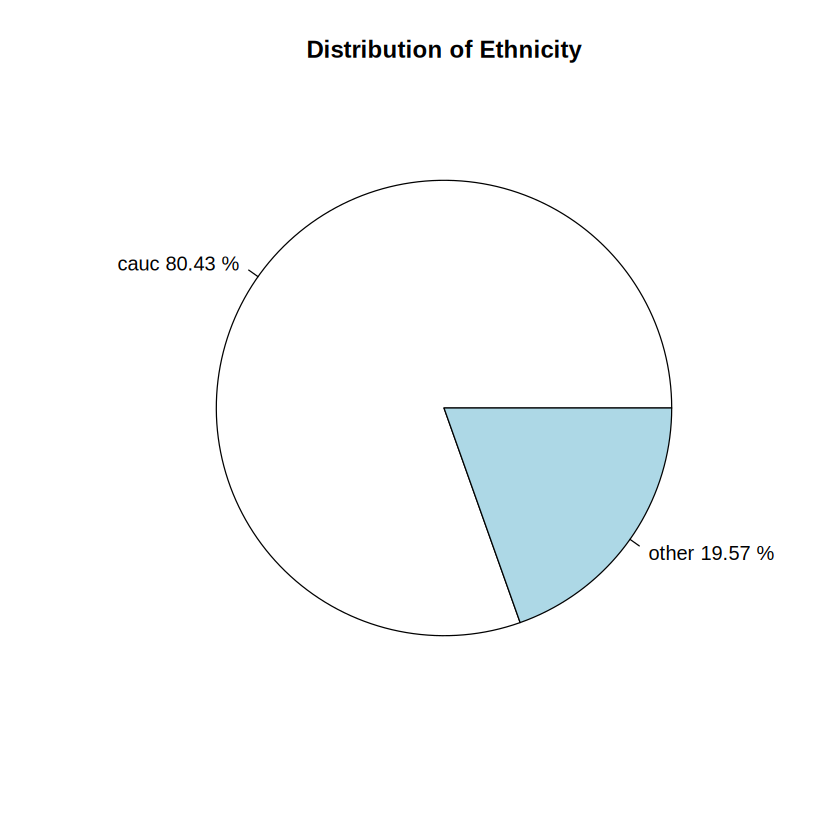

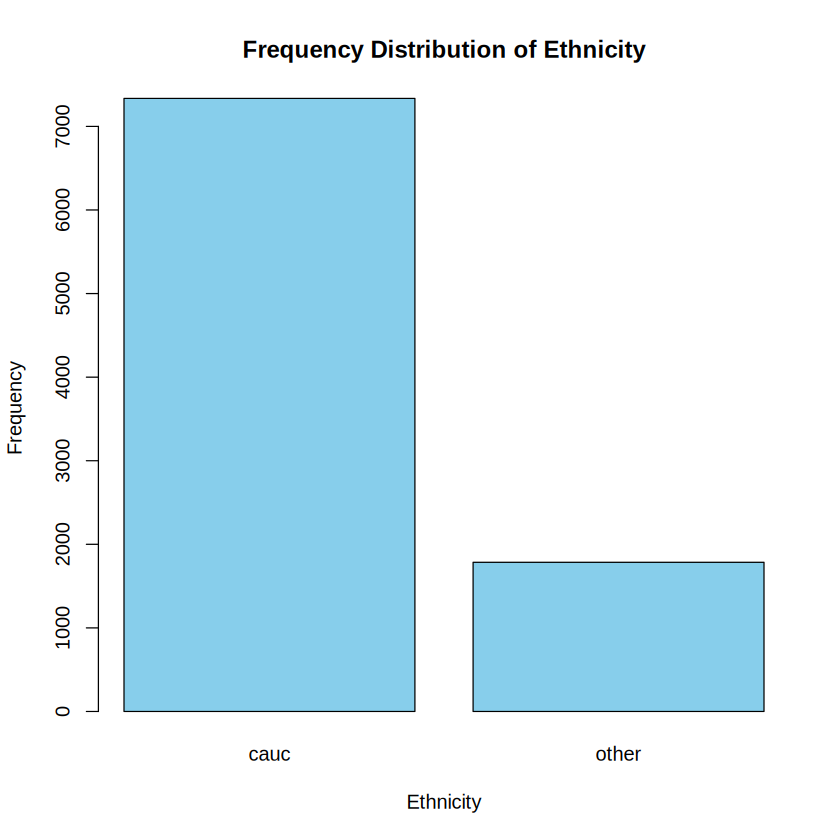

In [101]:
freq_ethnicity <- table(data$ethnicity)
print(freq_ethnicity)
relative_freq_ethnicity <- prop.table(freq_ethnicity)
print(relative_freq_ethnicity)
percentage_ethnicity <- prop.table(freq_ethnicity) * 100
print(percentage_ethnicity)
pie(
  freq_ethnicity,
  main = "Distribution of Ethnicity",
  labels = paste(
    names(freq_ethnicity),
    round(prop.table(freq_ethnicity) * 100, 2),
    "%"
  )
)
barplot(
  freq_ethnicity,
  main = "Frequency Distribution of Ethnicity",
  xlab = "Ethnicity",
  ylab = "Frequency",
  col = "skyblue"
)

**Q5.** Binned frequency table, histogram and box plot for a numerical variable.

[1] 18

[1] 89

age_groups
[10,20) [20,30) [30,40) [40,50) [50,60) [60,70) [70,80) [80,90] 
    131    1774    2065    1598    1279    1036     835     402 
age_groups
   [10,20)    [20,30)    [30,40)    [40,50)    [50,60)    [60,70)    [70,80) 
0.01436404 0.19451754 0.22642544 0.17521930 0.14024123 0.11359649 0.09155702 
   [80,90] 
0.04407895 


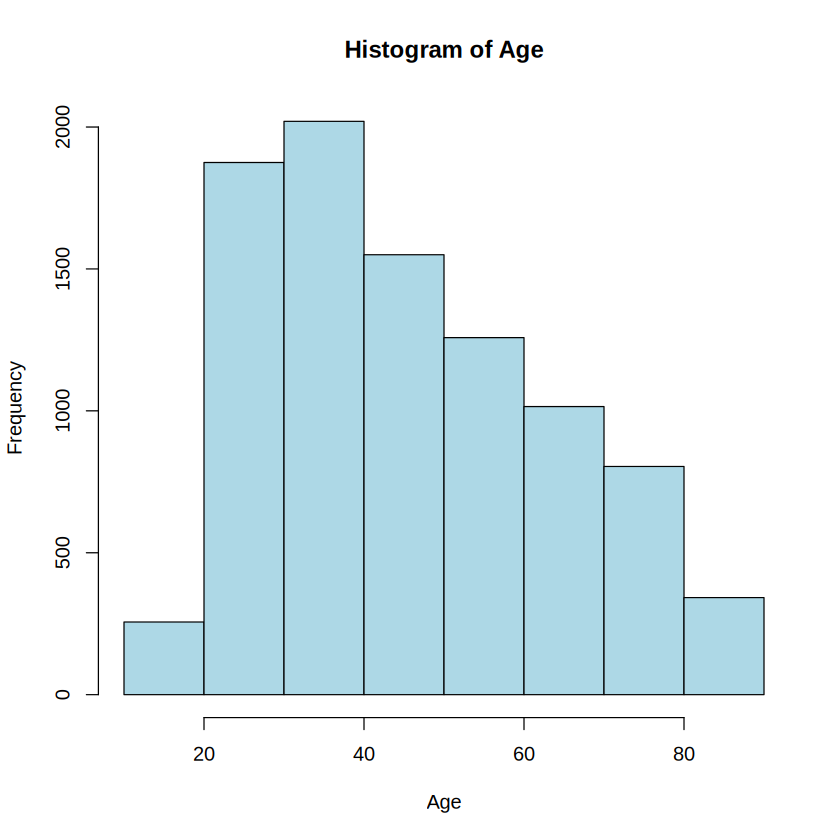

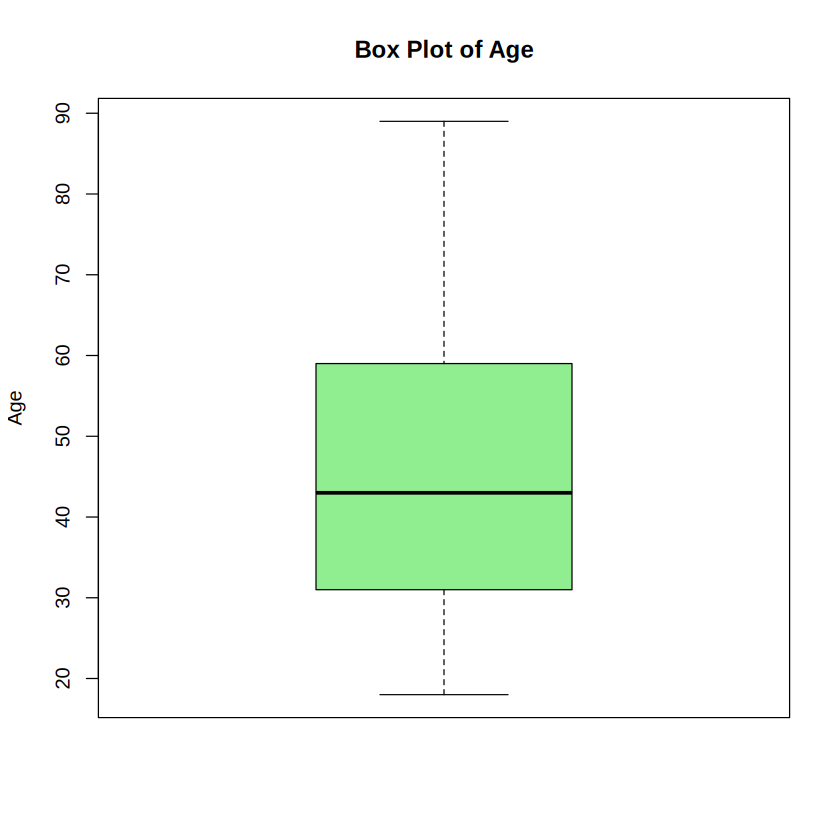

In [102]:
min(data$age, na.rm = TRUE)
max(data$age, na.rm = TRUE)
age_breaks <- seq(
  floor(min(data$age, na.rm = TRUE) / 10) * 10,
  ceiling(max(data$age, na.rm = TRUE) / 10) * 10,
  by = 10
)
age_groups <- cut(
  data$age,
  breaks = age_breaks,
  right = FALSE,
  include.lowest = TRUE
)
age_frequency <- table(age_groups)
print(age_frequency)
age_relative_frequency <- prop.table(age_frequency)
print(age_relative_frequency)
hist(
  data$age,
  breaks = age_breaks,
  main = "Histogram of Age",
  xlab = "Age",
  ylab = "Frequency",
  col = "lightblue",
  border = "black"
)
boxplot(
  data$age,
  main = "Box Plot of Age",
  ylab = "Age",
  col = "lightgreen"
)

**Q6.** Contingency table and row / column percentages.

In [103]:
contingency_table <- table(
  data$ethnicity,
  data$immigrant
)
print(contingency_table)
row_percentages <- prop.table(
  contingency_table,
  margin = 1
) * 100

print(row_percentages)
column_percentages <- prop.table(
  contingency_table,
  margin = 2
) * 100
print(column_percentages)
overall_percentages <- prop.table(
  contingency_table
) * 100
print(overall_percentages)

       
          no  yes
  cauc  6618  717
  other 1504  281
       
               no       yes
  cauc  90.224949  9.775051
  other 84.257703 15.742297
       
              no      yes
  cauc  81.48239 71.84369
  other 18.51761 28.15631
       
               no       yes
  cauc  72.565789  7.861842
  other 16.491228  3.081140


**Q7.** Stacked bar plot.

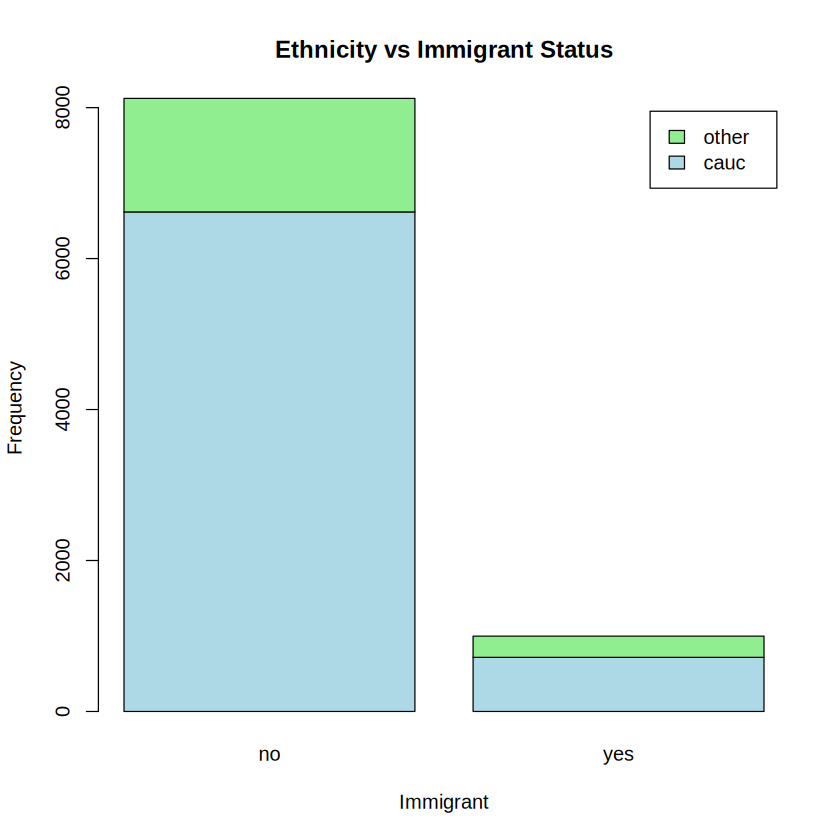

In [104]:
barplot(
  contingency_table,
  beside = FALSE,
  main = "Ethnicity vs Immigrant Status",
  xlab = "Immigrant",
  ylab = "Frequency",
  legend = rownames(contingency_table),
  col = c("lightblue", "lightgreen")
)

**Q8.** Mean, median and SD of a numerical variable grouped by category (`aggregate()`).

In [105]:
mean_by_ethnicity <- aggregate(
  age ~ ethnicity,
  data = data,
  FUN = mean,
  na.rm = TRUE
)
print(mean_by_ethnicity)
median_by_ethnicity <- aggregate(
  age ~ ethnicity,
  data = data,
  FUN = median,
  na.rm = TRUE
)
print(median_by_ethnicity)
sd_by_ethnicity <- aggregate(
  age ~ ethnicity,
  data = data,
  FUN = sd,
  na.rm = TRUE
)
print(sd_by_ethnicity)
grouped_statistics <- data.frame(
  Ethnicity = unique(data$ethnicity)
)
grouped_statistics$Mean <- tapply(
  data$age,
  data$ethnicity,
  mean,
  na.rm = TRUE
)
grouped_statistics$Median <- tapply(
  data$age,
  data$ethnicity,
  median,
  na.rm = TRUE
)
grouped_statistics$SD <- tapply(
  data$age,
  data$ethnicity,
  sd,
  na.rm = TRUE
)
print(grouped_statistics)

  ethnicity      age
1      cauc 47.09789
2     other 41.90756
  ethnicity age
1      cauc  44
2     other  38
  ethnicity      age
1      cauc 18.08202
2     other 16.62407
  Ethnicity     Mean Median       SD
1      cauc 47.09789     44 18.08202
2     other 41.90756     38 16.62407


**Q9.** Side-by-side box plots and violin plot.

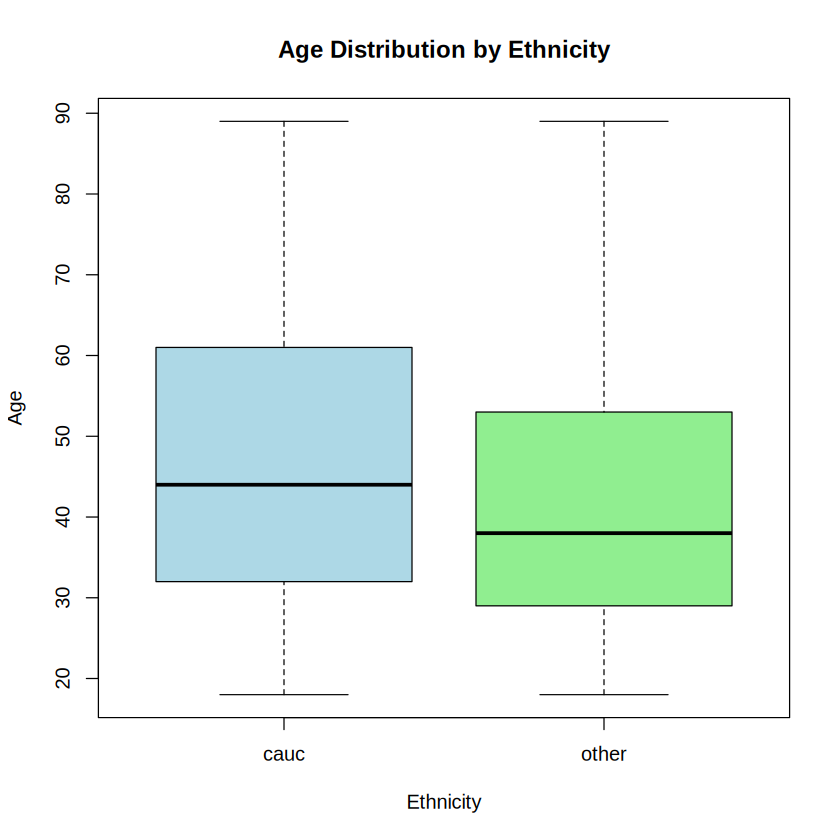

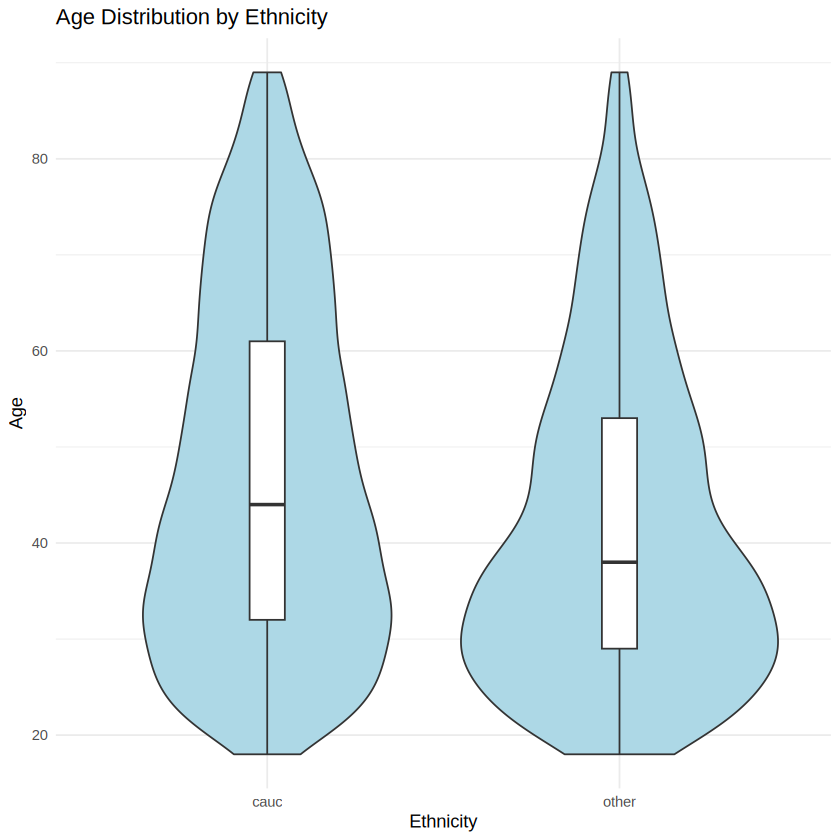

In [106]:
boxplot(
  age ~ ethnicity,
  data = data,
  main = "Age Distribution by Ethnicity",
  xlab = "Ethnicity",
  ylab = "Age",
  col = c("lightblue", "lightgreen")
)
ggplot(
  data,
  aes(
    x = ethnicity,
    y = age
  )
) +
  geom_violin(fill = "lightblue") +
  geom_boxplot(
    width = 0.1,
    fill = "white"
  ) +
  labs(
    title = "Age Distribution by Ethnicity",
    x = "Ethnicity",
    y = "Age"
  ) +
  theme_minimal()

**Q10.** Pearson and Spearman correlation + scatter plot with linear trend line.

[1] -0.2418432
[1] -0.1979367
    Method Correlation
1  Pearson  -0.2418432
2 Spearman  -0.1979367


`geom_smooth()` using formula = 'y ~ x'


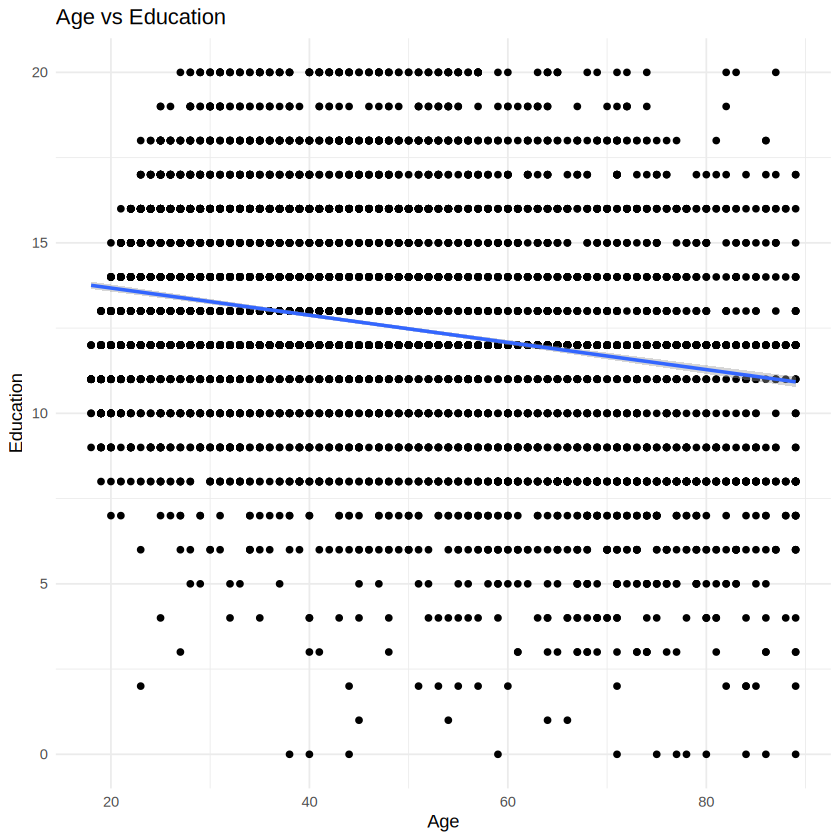

In [107]:
pearson_correlation <- cor(
  data$age,
  data$education,
  method = "pearson",
  use = "complete.obs"
)

print(pearson_correlation)
spearman_correlation <- cor(
  data$age,
  data$education,
  method = "spearman",
  use = "complete.obs"
)
print(spearman_correlation)
correlation_results <- data.frame(
  Method = c("Pearson", "Spearman"),
  Correlation = c(
    pearson_correlation,
    spearman_correlation
  )
)
print(correlation_results)
ggplot(
  data,
  aes(
    x = age,
    y = education
  )
) +
  geom_point() +
  geom_smooth(
    method = "lm",
    se = TRUE
  ) +
  labs(
    title = "Age vs Education",
    x = "Age",
    y = "Education"
  ) +
  theme_minimal()

**Q11.** Summary statistics across two categorical variables; faceted box plot and grouped bar chart with error bars.

  ethnicity immigrant      age
1      cauc        no 46.32729
2     other        no 42.55319
3      cauc       yes 54.21060
4     other       yes 38.45196
  ethnicity immigrant      age
1      cauc        no 17.77494
2     other        no 17.01117
3      cauc       yes 19.31390
4     other       yes 13.90087
# A tibble: 4 × 4
  ethnicity immigrant  Mean    SD
  <chr>     <chr>     <dbl> <dbl>
1 cauc      no         46.3  17.8
2 cauc      yes        54.2  19.3
3 other     no         42.6  17.0
4 other     yes        38.5  13.9


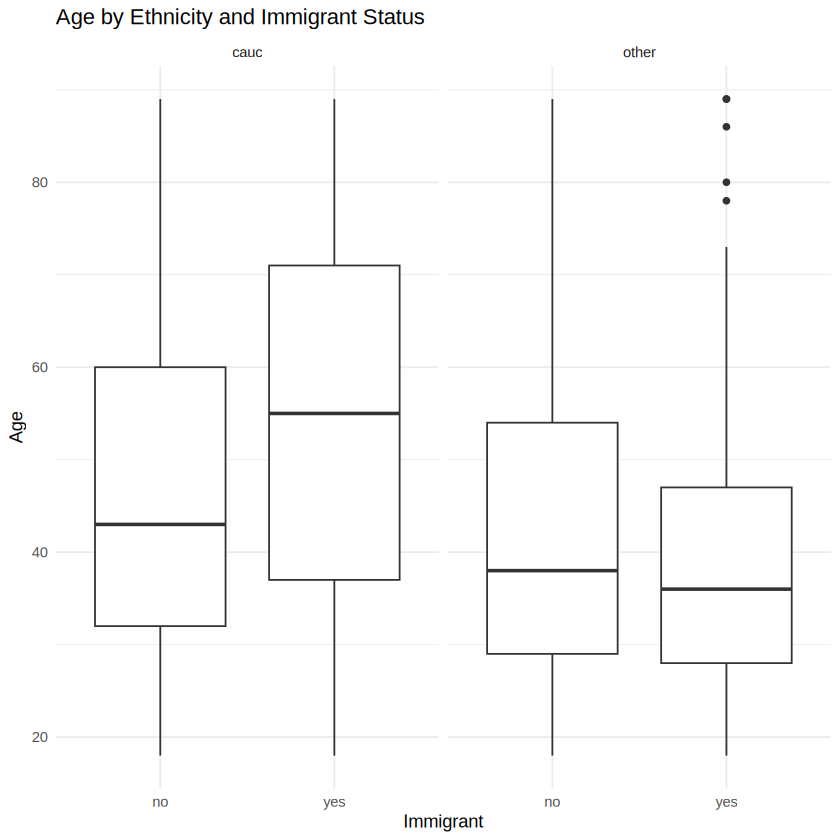

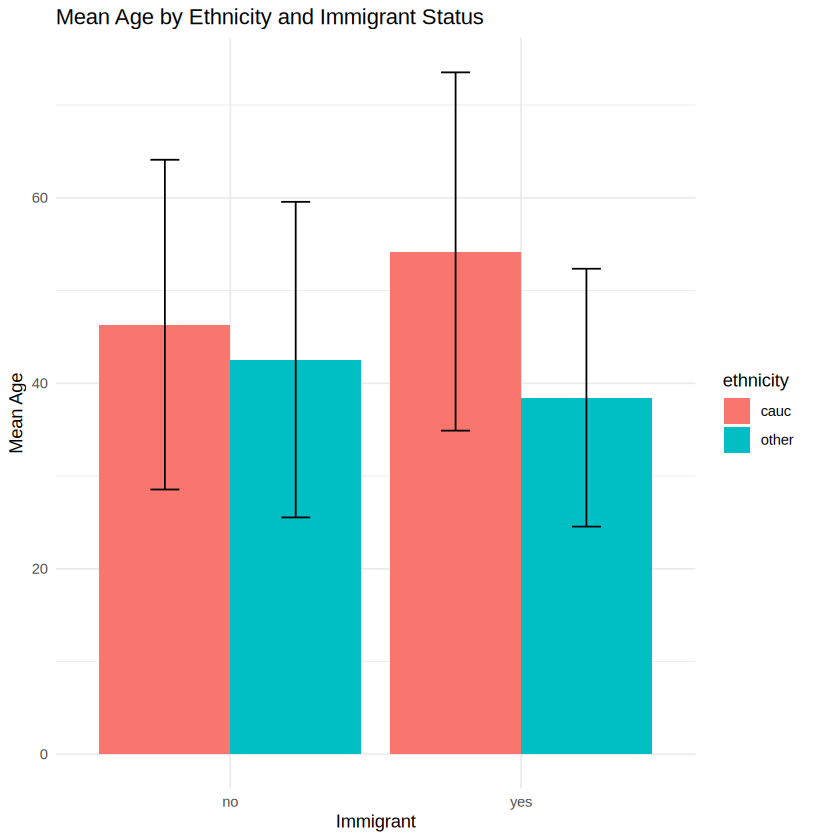

In [108]:
mean_combination <- aggregate(
  age ~ ethnicity + immigrant,
  data = data,
  FUN = mean,
  na.rm = TRUE
)
print(mean_combination)
sd_combination <- aggregate(
  age ~ ethnicity + immigrant,
  data = data,
  FUN = sd,
  na.rm = TRUE
)
print(sd_combination)
combination_summary <- data %>%
  group_by(
    ethnicity,
    immigrant
  ) %>%
  summarise(
    Mean = mean(age, na.rm = TRUE),
    SD = sd(age, na.rm = TRUE),
    .groups = "drop"
  )
print(combination_summary)
ggplot(
  data,
  aes(
    x = immigrant,
    y = age
  )
) +
  geom_boxplot() +
  facet_wrap(~ ethnicity) +
  labs(
    title = "Age by Ethnicity and Immigrant Status",
    x = "Immigrant",
    y = "Age"
  ) +
  theme_minimal()
ggplot(
  combination_summary,
  aes(
    x = immigrant,
    y = Mean,
    fill = ethnicity
  )
) +
  geom_bar(
    stat = "identity",
    position = position_dodge()
  ) +
  geom_errorbar(
    aes(
      ymin = Mean - SD,
      ymax = Mean + SD
    ),
    position = position_dodge(0.9),
    width = 0.2
  ) +
  labs(
    title = "Mean Age by Ethnicity and Immigrant Status",
    x = "Immigrant",
    y = "Mean Age"
  ) +
  theme_minimal()

**Q12.** Scatter plot coloured/shaped by category; correlation by category level.

# A tibble: 2 × 3
  ethnicity Pearson_Correlation Spearman_Correlation
  <chr>                   <dbl>                <dbl>
1 cauc                   -0.232               -0.202
2 other                  -0.357               -0.236


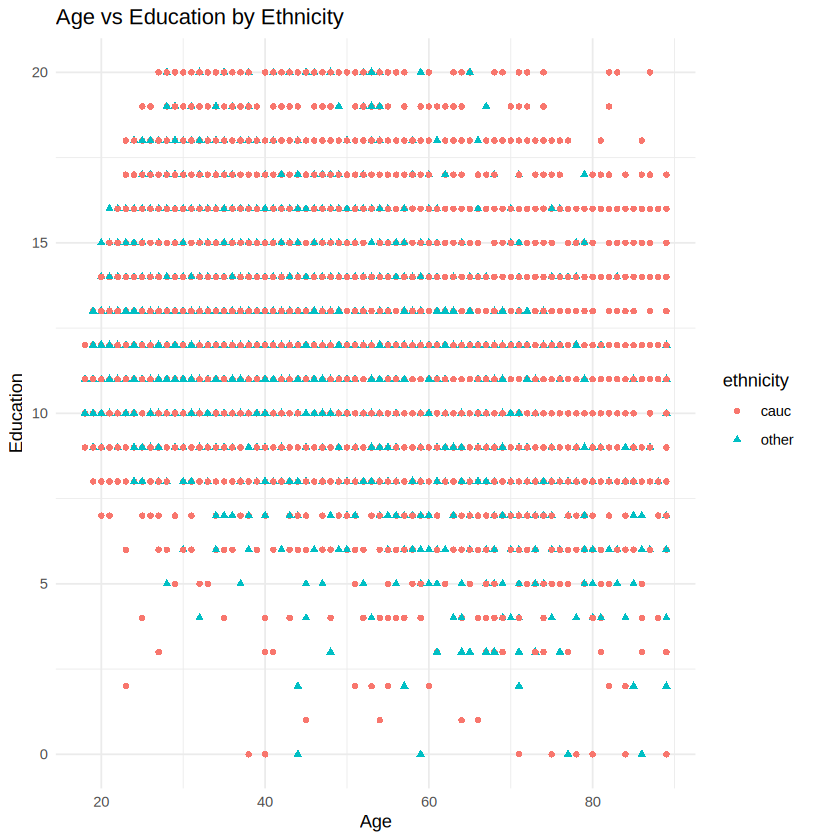

In [109]:
ggplot(
  data,
  aes(
    x = age,
    y = education,
    color = ethnicity,
    shape = ethnicity
  )
) +
  geom_point() +
  labs(
    title = "Age vs Education by Ethnicity",
    x = "Age",
    y = "Education"
  ) +
  theme_minimal()
cor_by_ethnicity <- data %>%
  group_by(ethnicity) %>%
  summarise(
    Pearson_Correlation = cor(
      age,
      education,
      method = "pearson",
      use = "complete.obs"
    ),
    Spearman_Correlation = cor(
      age,
      education,
      method = "spearman",
      use = "complete.obs"
    )
  )
print(cor_by_ethnicity)

**Q13.** Full correlation matrix and heatmap.

                    kids         age  education   siblings agefirstbirth
kids           1.0000000  0.32569202 -0.2905108  0.1800146   -0.28939529
age            0.3256920  1.00000000 -0.2418432  0.1097360    0.09922903
education     -0.2905108 -0.24184323  1.0000000 -0.2906031    0.36973661
siblings       0.1800146  0.10973599 -0.2906031  1.0000000   -0.11479190
agefirstbirth -0.2893953  0.09922903  0.3697366 -0.1147919    1.00000000


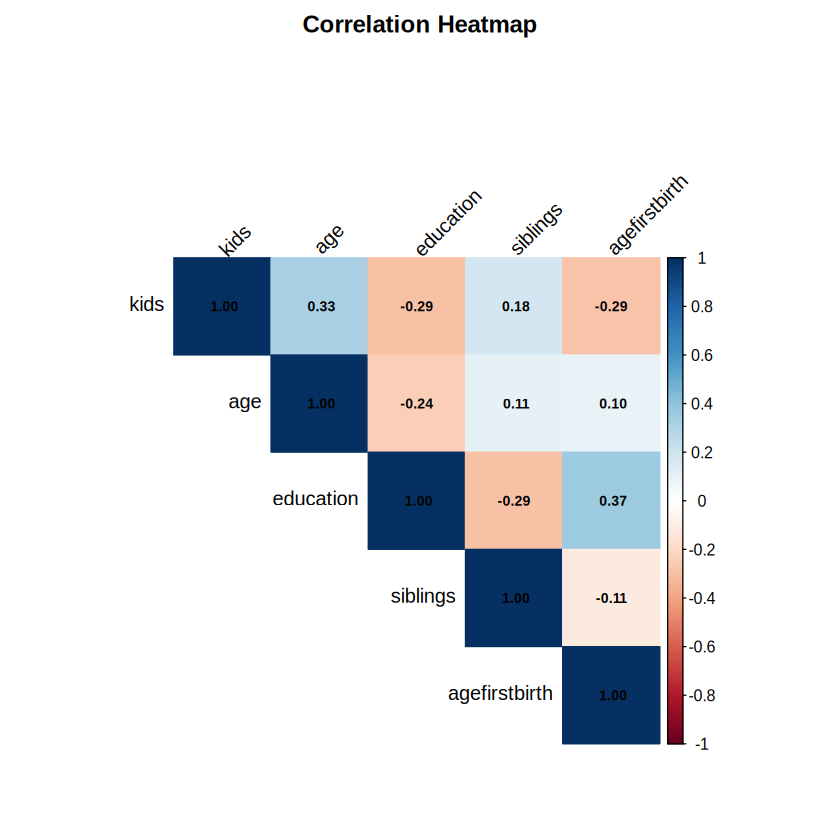

In [110]:
numeric_data <- data[
  c(
    "kids",
    "age",
    "education",
    "siblings",
    "agefirstbirth"
  )
]
correlation_matrix <- cor(
  numeric_data,
  use = "pairwise.complete.obs",
  method = "pearson"
)
print(correlation_matrix)
corrplot(
  correlation_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  tl.srt = 45,
  number.cex = 0.7,
  title = "Correlation Heatmap",
  mar = c(0, 0, 2, 0)
)

**Q14.** Pairs plot / scatterplot matrix and summary statistics of all numeric variables.

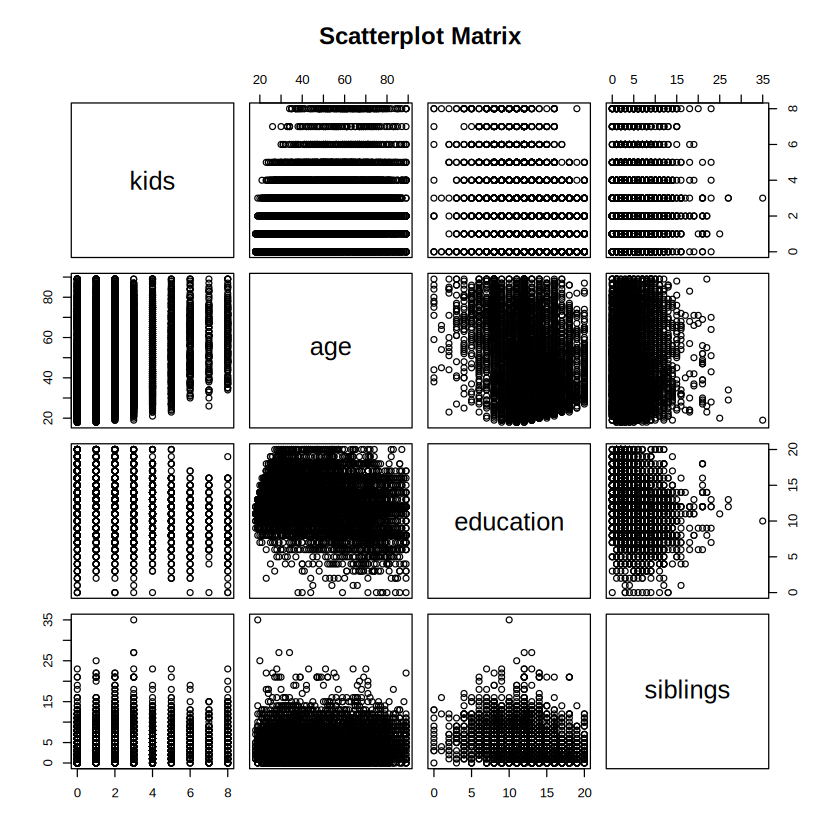

                   Variable      Mean Median Minimum Maximum Range   Variance
kids                   kids  2.076096      2       0       8     8   3.258382
age                     age 46.082018     43      18      89    71 321.265780
education         education 12.635088     12       0      20    20   8.733147
siblings           siblings  4.050658      3       0      35    35  10.537405
agefirstbirth agefirstbirth 22.630737     22       9      42    33  23.612018
                     SD IQR   Skewness   Kurtosis
kids           1.805099   2  0.9995832  1.0255954
age           17.923889  28  0.4764246 -0.7809245
education      2.955190   2 -0.2619139  1.0257926
siblings       3.246137   4  1.6707073  4.7836546
agefirstbirth  4.859220   6  0.8674822  0.5871508


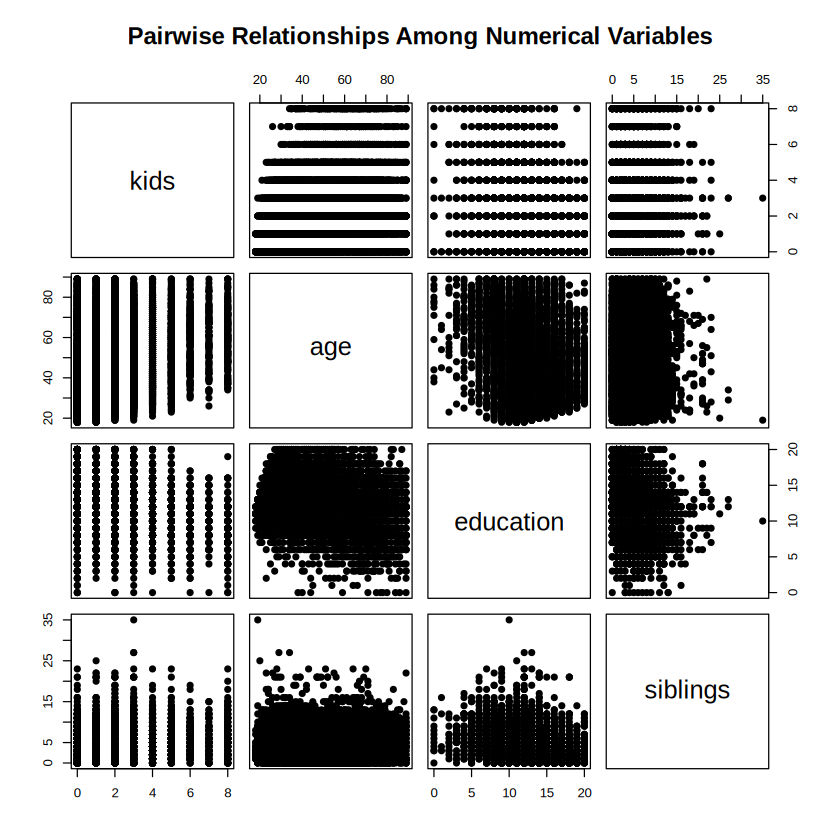

In [111]:
pairs_data <- data[
  c(
    "kids",
    "age",
    "education",
    "siblings"
  )
]
pairs(
  pairs_data,
  main = "Scatterplot Matrix"
)
pairs(
  pairs_data,
  main = "Pairwise Relationships Among Numerical Variables",
  pch = 19
)
summary_function <- function(x) {
  c(
    Mean = mean(x, na.rm = TRUE),
    Median = median(x, na.rm = TRUE),
    Minimum = min(x, na.rm = TRUE),
    Maximum = max(x, na.rm = TRUE),
    Range = max(x, na.rm = TRUE) - min(x, na.rm = TRUE),
    Variance = var(x, na.rm = TRUE),
    SD = sd(x, na.rm = TRUE),
    IQR = IQR(x, na.rm = TRUE),
    Skewness = e1071::skewness(x, na.rm = TRUE),
    Kurtosis = e1071::kurtosis(x, na.rm = TRUE)
  )
}
all_summary_statistics <- data.frame(
  Variable = c(
    "kids",
    "age",
    "education",
    "siblings",
    "agefirstbirth"
  ),
  t(
    sapply(
      data[
        c(
          "kids",
          "age",
          "education",
          "siblings",
          "agefirstbirth"
        )
      ],
      summary_function
    )
  )
)
print(all_summary_statistics)

---
# ASSESSMENT VIII — Clustering Techniques
## PART A: K-Means Clustering

**Q1.** Load the dataset.

In [112]:
library(readxl)
data <- read_excel(data_path)

**Q2.** View the dataset.

In [144]:
str(data)
summary(data)

'data.frame':	9120 obs. of  11 variables:
 $ rownames     : num  1 2 3 4 5 6 7 8 9 10 ...
 $ kids         : num  0 1 1 2 2 0 0 0 1 3 ...
 $ age          : num  25 30 55 57 71 19 71 30 35 51 ...
 $ education    : num  14 13 2 16 12 13 12 12 12 12 ...
 $ year         : num  2002 2002 2002 2002 2002 ...
 $ siblings     : num  1 4 1 1 6 1 1 5 0 1 ...
 $ agefirstbirth: num  NA 19 27 22 29 NA NA NA 21 20 ...
 $ ethnicity    : chr  "cauc" "cauc" "cauc" "cauc" ...
 $ city16       : chr  "no" "yes" "no" "no" ...
 $ lowincome16  : chr  "no" "no" "no" "no" ...
 $ immigrant    : chr  "no" "no" "yes" "no" ...


    rownames         kids            age          education          year     
 Min.   :   1   Min.   :0.000   Min.   :18.00   Min.   : 0.00   Min.   :1974  
 1st Qu.:2281   1st Qu.:1.000   1st Qu.:31.00   1st Qu.:12.00   1st Qu.:1982  
 Median :4560   Median :2.000   Median :43.00   Median :12.00   Median :1994  
 Mean   :4560   Mean   :2.076   Mean   :46.08   Mean   :12.64   Mean   :1990  
 3rd Qu.:6840   3rd Qu.:3.000   3rd Qu.:59.00   3rd Qu.:14.00   3rd Qu.:1998  
 Max.   :9120   Max.   :8.000   Max.   :89.00   Max.   :20.00   Max.   :2002  
                                                                              
    siblings      agefirstbirth       ethnicity          city16    
 Min.   : 0.000   Min.   : 9.00   Length   :9120   Length   :9120  
 1st Qu.: 2.000   1st Qu.:19.00   N.unique :   2   N.unique :   2  
 Median : 3.000   Median :22.00   N.blank  :   0   N.blank  :   0  
 Mean   : 4.051   Mean   :22.63   Min.nchar:   4   Min.nchar:   2  
 3rd Qu.: 6.000   3rd Qu.:25

**Q3.** Check missing values.

In [114]:
colSums(is.na(data))

rownames          kids           age     education          year 
            0             0             0             0             0 
     siblings agefirstbirth     ethnicity        city16   lowincome16 
            0          5808             0             0             0 
    immigrant 
            0

**Q4.** Distribution of categorical variables (`table`).

In [115]:
table(data$ethnicity)
table(data$city16)
table(data$lowincome16)
table(data$immigrant)


 cauc other 
 7335  1785 


  no  yes 
5246 3874 


  no  yes 
7182 1938 


  no  yes 
8122  998 

**Q5.** Select only numerical features for K-Means.

In [116]:
numeric_data <- data[sapply(data, is.numeric)]
numeric_data <- numeric_data[, !names(numeric_data) %in% "rownames"]
numeric_data <- na.omit(numeric_data)

**Q6.** Standardize the data (`scale`).

In [117]:
scaled_data <- scale(numeric_data)
head(scaled_data)

kids,age,education,year,siblings,agefirstbirth
-1.0798386,-1.1244886,0.03689781,1.179615,-0.01886157,-0.7471851
-1.0798386,0.3615011,-3.88223089,1.179615,-0.90705365,0.8991697
-0.3851173,0.4803802,1.10575110,1.179615,-0.90705365,-0.1298021
-0.3851173,1.3125344,-0.31938661,1.179615,0.57326649,1.3107584
-1.0798386,-0.8272906,-0.31938661,1.179615,-1.20311768,-0.3355964
0.3096041,0.1237427,-0.31938661,1.179615,-0.90705365,-0.5413908


**Q7.** K-Means with 2 centres.

In [118]:
set.seed(123)
kmeans_2 <- kmeans(scaled_data, centers = 2, nstart = 25)

**Q8.** Display K-Means results.

In [119]:
kmeans_2
kmeans_2$cluster
table(kmeans_2$cluster)

K-means clustering with 2 clusters of sizes 1235, 2077

Cluster means:
        kids        age  education        year   siblings agefirstbirth
1  0.7247493  0.6090297 -0.6543228 -0.07582672  0.4438134    -0.5138960
2 -0.4309415 -0.3621337  0.3890653  0.04508714 -0.2638948     0.3055664

Clustering vector:
   [1] 2 1 2 2 2 2 1 2 1 1 2 1 2 2 2 1 1 2 1 2 2 1 2 2 2 2 1 1 1 1 2 2 2 2 1 2 2
  [38] 2 2 2 2 1 1 2 1 2 2 2 1 2 1 1 2 2 2 2 2 2 1 2 1 2 1 1 1 2 2 2 2 2 2 2 2 2
  [75] 1 2 2 2 2 2 2 2 2 2 1 2 2 1 2 2 1 2 2 1 2 1 2 2 2 2 2 1 1 1 2 2 1 1 2 1 1
 [112] 2 1 2 2 1 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 2 2 2 1 2 2 2 2 2 2
 [149] 2 2 2 2 1 2 1 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 1 2 2 2 1 1 1 2 1 2
 [186] 2 2 1 2 2 1 2 1 2 1 1 2 1 2 2 2 2 2 2 2 2 1 1 1 2 2 2 2 2 2 2 1 2 2 2 1 2
 [223] 2 2 2 2 1 2 2 1 2 2 2 2 2 2 2 1 1 1 2 1 2 2 2 1 1 2 2 2 1 1 1 1 1 2 2 1 2
 [260] 2 2 1 2 2 2 2 1 2 2 2 1 1 1 1 2 1 2 2 1 2 1 2 2 2 2 2 2 2 1 1 2 2 2 2 1 2
 [297] 1 2 1 1 2 1 1 2 2 2 1 1 2 2 2 1 2 1 2 

[1] 2 1 2 2 2 2 1 2 1 1 2 1 2 2 2 1 1 2 1 2 2 1 2 2 2 2 1 1 1 1 2 2 2 2 1 2 2
  [38] 2 2 2 2 1 1 2 1 2 2 2 1 2 1 1 2 2 2 2 2 2 1 2 1 2 1 1 1 2 2 2 2 2 2 2 2 2
  [75] 1 2 2 2 2 2 2 2 2 2 1 2 2 1 2 2 1 2 2 1 2 1 2 2 2 2 2 1 1 1 2 2 1 1 2 1 1
 [112] 2 1 2 2 1 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 2 2 2 1 2 2 2 2 2 2
 [149] 2 2 2 2 1 2 1 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 1 2 2 2 1 1 1 2 1 2
 [186] 2 2 1 2 2 1 2 1 2 1 1 2 1 2 2 2 2 2 2 2 2 1 1 1 2 2 2 2 2 2 2 1 2 2 2 1 2
 [223] 2 2 2 2 1 2 2 1 2 2 2 2 2 2 2 1 1 1 2 1 2 2 2 1 1 2 2 2 1 1 1 1 1 2 2 1 2
 [260] 2 2 1 2 2 2 2 1 2 2 2 1 1 1 1 2 1 2 2 1 2 1 2 2 2 2 2 2 2 1 1 2 2 2 2 1 2
 [297] 1 2 1 1 2 1 1 2 2 2 1 1 2 2 2 1 2 1 2 1 2 1 2 1 1 2 2 2 2 2 2 2 2 1 1 2 2
 [334] 2 2 1 1 1 2 1 2 1 1 2 1 1 2 1 1 2 1 1 2 2 2 1 1 2 2 2 2 2 2 2 2 2 1 2 2 2
 [371] 2 2 2 2 1 2 2 2 1 2 2 1 1 1 2 2 2 1 1 2 2 2 1 2 2 1 2 2 2 1 2 2 1 2 2 2 2
 [408] 2 1 2 1 2 1 2 1 2 1 1 2 1 1 2 1 1 1 2 1 1 2 2 1 2 1 1 2 2 2 2 1 1 2 2 2 2
 [445] 2 1 2 2 2 1 2 2 1 2 2 2 2 1 2 2 2 1 2 2 2 1 1 2 2 2 2 2 2 2 2 2 2 1 2 2 2
 [482] 2 1 1 2 2 2 1 2 2 2 2 2 2 2 2 2 2 1 1 2 2 1 1 1 1 2 1 1 1 1 2 2 2 2 2 2 1
 [519] 1 2 1 2 2 2 2 2 1 2 2 2 2 1 2 1 2 2 2 2 1 1 2 2 1 2 1 2 1 2 2 1 2 2 2 1 2
 [556] 2 2 2 2 1 2 1 1 2 1 1 1 2 1 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 1 2
 [593] 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 2 1 2 2 2 2 2 1 1 2 1 2 1 2 2 2 1 2 2 2 2 2
 [630] 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 2 1 1 2 2 2 1 2 2 2 1 2 2 2 2
 [667] 2 2 2 1 2 2 2 2 1 2 1 2 2 1 2 2 2 2 1 2 2 2 2 1 1 1 2 1 2 2 2 1 2 2 1 1 2
 [704] 1 1 1 1 2 2 2 2 2 1 1 2 1 2 2 1 2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 2 1 2 2 1 2
 [741] 2 2 2 1 2 2 2 2 2 2 1 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 2 2 1 1 1 2 1 2 2 2 2
 [778] 2 2 2 2 1 2 2 2 2 2 1 1 1 1 2 1 1 2 1 2 1 2 2 2 2 2 2 2 2 1 2 2 1 2 1 2 2
 [815] 2 2 1 2 1 2 2 1 1 2 2 2 1 1 2 1 1 2 1 2 1 1 2 2 1 2 1 2 2 2 2 1 1 1 2 2 2
 [852] 2 2 2 2 2 1 1 2 2 1 1 2 2 2 1 2 2 1 2 1 2 2 1 2 1 2 1 2 1 2 2 2 2 2 1 2 2
 [889] 2 1 2 1 2 1 2 1 2 2 1 2 2 2 2 2 2 1 1 1 2 2 1 2 2 2 2 2 1 2 1 1 1 1 1 1 2
 [926] 2 1 2 1 2 2 2 1 1 2 1 1 2 1 1 2 2 2 2 2 1 1 1 2 2 1 1 2 1 2 2 2 2 1 2 2 1
 [963] 1 1 1 1 1 2 2 1 2 2 1 2 2 2 2 2 2 2 2 2 2 1 1 2 2 2 2 2 2 1 2 2 2 2 2 2 2
[1000] 2 2 2 2 1 1 1 2 2 1 2 2 2 2 2 2 2 1 2 2 2 1 2 2 2 2 1 1 1 2 2 2 1 2 1 1 1
[1037] 1 1 2 2 2 1 1 2 2 1 2 2 2 2 2 2 2 2 2 1 1 2 2 2 1 2 1 2 1 2 1 2 2 1 2 2 2
[1074] 1 2 2 2 2 2 1 2 2 2 1 2 2 2 1 1 2 1 2 2 2 2 2 2 1 2 2 2 2 1 2 2 1 1 2 1 2
[1111] 2 1 2 2 1 1 1 1 2 2 2 2 2 2 2 1 2 2 2 1 2 1 2 2 2 2 2 2 2 2 2 1 1 1 2 1 1
[1148] 1 2 1 2 1 1 2 2 2 1 2 1 1 2 2 2 1 2 1 1 2 2 2 2 1 1 1 1 1 1 1 2 2 1 2 2 1
[1185] 2 1 2 1 1 2 2 2 1 2 2 2 2 2 1 2 2 2 2 2 2 2 1 1 1 2 1 1 2 2 2 2 2 2 2 2 2
[1222] 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 2 2 2 1 2 2 2 1 1 1 2 2 2 2 1 1
[1259] 1 2 1 1 1 2 1 1 2 2 1 2 1 2 2 2 2 2 2 2 1 2 2 2 1 2 1 1 2 2 2 2 2 2 1 1 2
[1296] 2 2 2 1 1 2 2 2 2 1 1 1 1 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 2 2 1 2 1 1
[1333] 2 2 2 1 1 2 2 2 2 1 1 1 1 1 1 1 2 1 1 2 2 1 2 1 2 2 2 1 2 2 1 2 1 1 1 2 2
[1370] 2 2 1 1 2 2 2 2 1 1 2 1 2 1 1 2 1 2 1 2 1 2 1 2 2 2 2 2 2 2 2 2 2 1 2 2 2
[1407] 2 2 2 2 2 1 1 1 2 1 2 2 2 2 1 2 2 1 2 2 1 2 1 1 1 1 2 2 2 2 1 1 2 1 2 1 2
[1444] 2 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 2 2 1 2 2 2 1 2 2 2 1 2 2 2 1 2 2 1 1 1 1
[1481] 1 1 1 2 1 2 2 2 2 1 2 2 1 1 1 2 2 2 2 2 2 2 1 2 2 1 2 2 2 1 2 2 2 1 1 2 2
[1518] 2 2 2 1 1 2 2 1 2 1 2 1 2 2 2 2 1 2 1 1 1 2 1 2 1 1 1 2 1 2 2 2 1 2 1 2 1
[1555] 2 1 1 1 2 1 2 2 2 1 1 2 1 1 1 1 2 2 2 2 2 2 1 2 2 2 1 2 2 1 1 2 2 2 2 1 1
[1592] 1 2 2 2 2 2 1 2 1 1 1 2 2 2 1 2 2 2 2 1 1 2 2 1 1 2 2 1 2 1 1 2 2 2 2 1 1
[1629] 1 2 2 1 2 1 1 2 2 2 1 2 1 2 1 1 1 2 1 1 1 2 2 1 2 2 2 2 1 1 1 1 2 1 1 2 2
[1666] 1 2 2 1 2 1 1 2 1 1 2 2 2 2 2 2 2 2 1 2 1 2 2 1 1 2 2 2 2 2 2 1 2 1 1 2 1
[1703] 1 2 2 2 1 2 2 2 1 2 2 2 1 2 2 2 1 1 1 1 2 2 2 1 2 2 2 2 1 2 1 1 1 2 1 1 1
[1740] 2 2 2 2 1 1 2 2 2 1 1 2 1 1 2 2 2 2 2 1 1 1 2 2 2 2 2 1 2 2 2 2 1 2 2 2 2
[1777] 1 2 2 2 2 1 1 1 2 2 2 2 2 1 1 2 2 2 2 2 1 2 2 2 2 2 1 1 1 2 1 2 2 1 2 2 2
[1814] 2 1 1 1 2 2 2 2 2 2 2 2 2 1


   1    2 
1235 2077 

**Q9.** Cluster centres.

In [120]:
kmeans_2$centers

,kids,age,education,year,siblings,agefirstbirth
1,0.7247493,0.6090297,-0.6543228,-0.07582672,0.4438134,-0.5138960
2,-0.4309415,-0.3621337,0.3890653,0.04508714,-0.2638948,0.3055664


**Q10.** WCSS for K = 1 to 10.

In [121]:
wcss <- numeric(10)

set.seed(123)

for (k in 1:10) {
  km <- kmeans(scaled_data, centers = k, nstart = 25)
  wcss[k] <- km$tot.withinss
}
wcss

Warning message:
“did not converge in 10 iterations”
Warning message:
“did not converge in 10 iterations”
Warning message:
“did not converge in 10 iterations”


[1] 19866.000 16338.663 14104.417 12748.365 11527.717 10526.101  9922.224
 [8]  9378.366  9005.852  8650.736

**Q11.** Elbow plot.

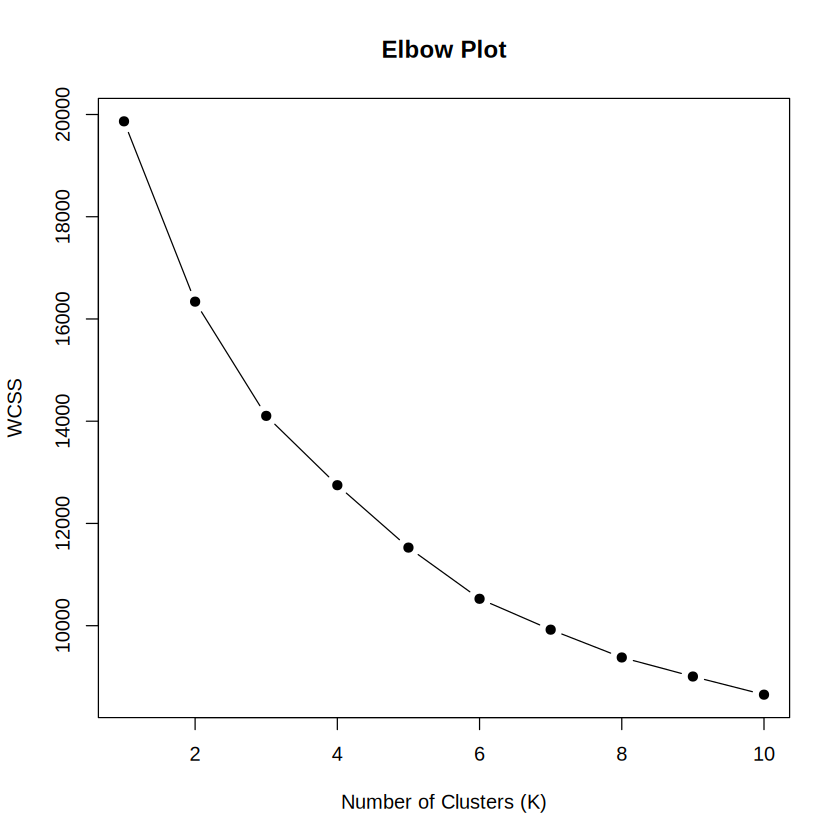

In [122]:
plot(
  1:10,
  wcss,
  type = "b",
  pch = 19,
  xlab = "Number of Clusters (K)",
  ylab = "WCSS",
  main = "Elbow Plot"
)

**Q12.** K-Means based on the elbow recommendation.

In [123]:
elbow_k <- 3

set.seed(123)

kmeans_elbow <- kmeans(
  scaled_data,
  centers = elbow_k,
  nstart = 25
)

kmeans_elbow
kmeans_elbow$cluster
kmeans_elbow$centers
table(kmeans_elbow$cluster)

K-means clustering with 3 clusters of sizes 1372, 1047, 893

Cluster means:
        kids         age  education        year   siblings agefirstbirth
1 -0.2914413 -0.70745835 -0.1812355  0.01664609  0.0232175    -0.5350909
2 -0.3924162  0.03665551  0.8399840  0.00282045 -0.3129462     1.0361694
3  0.9078580  1.04395804 -0.7063921 -0.02888180  0.3312433    -0.3927487

Clustering vector:
   [1] 1 3 2 2 1 1 3 2 3 3 1 1 1 2 1 1 1 1 3 2 2 3 1 1 2 1 3 3 3 3 1 1 2 2 3 2 2
  [38] 2 2 1 2 3 1 1 3 2 2 1 3 3 3 3 2 1 2 2 3 2 3 2 3 1 3 3 3 2 1 2 1 2 2 2 2 2
  [75] 3 3 2 1 2 2 2 2 2 2 3 1 1 3 2 1 3 2 1 3 1 3 1 2 1 1 1 3 1 3 2 1 1 3 2 3 3
 [112] 2 3 2 2 3 1 2 2 2 3 2 1 2 2 2 2 2 2 2 1 1 2 2 2 1 3 3 2 1 1 3 3 3 2 2 1 1
 [149] 2 2 1 2 3 1 1 2 1 1 1 1 2 1 2 1 1 1 1 2 2 1 1 1 3 1 3 3 2 2 2 3 3 3 3 3 1
 [186] 2 2 3 1 1 3 1 1 1 1 3 2 1 2 3 2 2 2 1 1 2 3 3 1 1 1 2 2 2 1 1 3 1 2 2 3 2
 [223] 3 2 2 1 1 2 1 3 1 1 1 2 2 1 1 1 1 3 2 3 1 2 1 3 3 2 2 1 1 3 3 3 1 1 1 3 2
 [260] 2 1 3 1 1 2 1 3 2 2 2 3 3 3 3 2 3 2 2 

[1] 1 3 2 2 1 1 3 2 3 3 1 1 1 2 1 1 1 1 3 2 2 3 1 1 2 1 3 3 3 3 1 1 2 2 3 2 2
  [38] 2 2 1 2 3 1 1 3 2 2 1 3 3 3 3 2 1 2 2 3 2 3 2 3 1 3 3 3 2 1 2 1 2 2 2 2 2
  [75] 3 3 2 1 2 2 2 2 2 2 3 1 1 3 2 1 3 2 1 3 1 3 1 2 1 1 1 3 1 3 2 1 1 3 2 3 3
 [112] 2 3 2 2 3 1 2 2 2 3 2 1 2 2 2 2 2 2 2 1 1 2 2 2 1 3 3 2 1 1 3 3 3 2 2 1 1
 [149] 2 2 1 2 3 1 1 2 1 1 1 1 2 1 2 1 1 1 1 2 2 1 1 1 3 1 3 3 2 2 2 3 3 3 3 3 1
 [186] 2 2 3 1 1 3 1 1 1 1 3 2 1 2 3 2 2 2 1 1 2 3 3 1 1 1 2 2 2 1 1 3 1 2 2 3 2
 [223] 3 2 2 1 1 2 1 3 1 1 1 2 2 1 1 1 1 3 2 3 1 2 1 3 3 2 2 1 1 3 3 3 1 1 1 3 2
 [260] 2 1 3 1 1 2 1 3 2 2 2 3 3 3 3 2 3 2 2 3 2 3 2 2 1 2 1 1 1 3 3 1 1 1 1 3 1
 [297] 1 2 3 3 2 3 3 1 2 1 3 3 1 1 1 3 2 3 2 3 2 3 2 3 3 2 2 2 2 2 2 2 1 3 3 1 1
 [334] 1 1 3 3 3 2 3 2 3 1 1 1 3 1 1 1 1 1 3 1 1 1 3 1 1 2 1 2 1 2 1 1 1 3 1 2 2
 [371] 1 2 1 2 3 1 1 2 2 2 2 3 3 3 1 1 2 3 3 2 2 1 1 1 1 3 1 1 2 3 1 1 3 2 2 1 1
 [408] 1 3 1 3 1 3 1 3 2 3 3 1 3 3 1 3 3 3 1 1 3 1 1 3 1 1 3 2 1 1 2 3 3 2 3 2 2
 [445] 1 1 2 2 2 3 1 1 3 2 1 2 2 3 2 1 1 3 2 2 2 1 3 1 1 1 2 1 2 1 2 1 1 1 2 1 2
 [482] 1 3 3 1 2 2 3 2 2 2 2 1 2 2 2 2 2 3 3 2 1 1 3 3 3 2 3 3 1 3 1 1 1 2 2 1 3
 [519] 3 1 3 1 1 2 2 2 1 2 1 2 1 1 2 1 1 1 1 1 3 3 1 1 3 2 1 2 3 1 1 3 2 1 2 1 1
 [556] 1 2 2 1 1 1 3 3 3 3 1 1 1 3 1 2 2 2 1 1 2 1 1 3 2 2 2 2 1 2 2 2 2 1 2 3 2
 [593] 1 1 1 2 1 1 1 1 2 1 2 2 3 3 3 2 3 1 1 1 1 2 3 3 2 3 2 1 2 2 1 3 1 1 2 2 1
 [630] 2 1 1 1 1 1 2 1 2 1 2 2 2 2 2 1 2 2 3 1 3 1 1 1 1 1 1 1 3 1 2 1 3 2 2 1 2
 [667] 2 1 1 3 1 2 1 2 1 2 1 1 1 1 2 2 2 1 3 1 2 2 2 3 3 1 1 3 1 1 1 3 1 1 1 1 1
 [704] 1 1 1 1 1 1 2 1 2 3 3 1 3 2 2 3 2 1 1 2 2 1 2 2 1 2 3 1 1 3 1 2 3 1 1 3 2
 [741] 1 2 1 3 2 2 2 2 1 1 3 2 2 2 2 3 2 3 2 2 2 2 2 2 1 3 2 1 1 3 1 1 3 2 2 2 2
 [778] 2 2 2 2 3 1 2 1 1 1 3 3 3 3 2 3 3 1 3 2 3 1 1 1 1 2 2 1 2 3 2 1 3 1 1 2 1
 [815] 1 1 3 2 3 2 1 3 3 2 2 2 3 3 1 3 1 2 1 1 3 3 2 1 3 2 1 2 2 2 2 1 3 3 1 2 2
 [852] 2 2 2 2 1 3 3 1 1 3 3 2 2 2 3 2 1 3 1 3 2 2 1 1 3 1 3 2 3 1 1 1 1 1 3 1 3
 [889] 1 3 1 3 1 3 2 1 1 1 3 1 1 1 1 1 1 3 1 3 2 1 3 1 1 1 1 1 1 1 3 3 1 3 1 1 1
 [926] 1 1 1 3 1 1 1 3 1 2 1 3 1 1 3 1 1 1 1 2 3 3 3 2 1 3 3 1 3 2 1 1 1 3 2 1 3
 [963] 3 1 3 1 1 1 1 3 1 1 1 2 2 2 2 2 1 1 1 1 2 3 3 2 1 1 1 1 1 3 1 2 3 2 2 2 2
[1000] 2 2 2 1 1 3 3 1 2 3 1 1 1 1 2 1 1 1 1 2 1 3 2 2 1 1 1 1 3 3 2 1 3 1 3 1 3
[1037] 1 3 2 2 1 1 3 2 2 3 2 1 2 2 1 1 2 2 1 3 3 2 2 2 3 1 3 1 3 2 3 1 2 1 2 1 1
[1074] 1 1 1 2 1 2 3 2 1 3 3 1 1 1 3 3 1 1 2 2 2 1 2 1 3 1 1 2 1 3 2 1 3 1 2 3 2
[1111] 2 1 1 2 3 3 1 3 1 1 1 1 1 1 2 3 1 2 1 3 1 3 1 1 1 1 1 1 1 1 2 3 3 3 2 1 3
[1148] 3 2 2 2 3 1 1 2 2 3 1 3 3 1 2 2 3 2 3 1 2 2 1 2 1 1 1 3 3 1 3 1 2 3 2 2 3
[1185] 2 3 2 1 3 1 2 1 3 2 1 1 2 1 2 2 2 2 1 2 2 2 3 3 3 2 1 3 2 2 2 2 1 2 2 2 2
[1222] 1 3 2 2 1 1 2 1 2 2 1 1 2 2 2 1 2 1 1 1 1 1 2 1 3 1 1 2 3 1 1 2 2 2 1 3 3
[1259] 3 1 3 3 3 1 3 3 1 2 3 2 3 2 2 1 1 2 2 1 1 2 1 1 3 2 3 1 1 2 1 1 2 2 1 3 2
[1296] 2 2 2 3 2 2 1 1 1 1 3 1 1 2 3 2 1 1 1 2 2 2 2 2 2 2 2 2 1 3 3 1 1 1 1 1 3
[1333] 1 2 2 3 3 2 1 2 2 3 1 3 3 3 1 1 1 1 3 1 1 3 1 3 1 2 1 1 2 1 1 2 3 3 3 2 1
[1370] 2 2 3 3 1 2 1 1 3 3 1 1 1 3 3 2 3 1 3 2 3 2 3 2 2 2 2 2 2 2 2 1 1 3 1 2 2
[1407] 2 2 1 2 1 1 1 3 2 3 1 2 2 2 1 1 1 3 2 2 3 1 1 1 1 1 2 1 1 1 3 1 1 1 1 1 1
[1444] 1 2 2 1 2 2 1 1 3 2 1 1 1 2 1 1 2 2 3 1 2 2 3 2 2 2 3 1 1 1 1 2 1 1 3 3 3
[1481] 3 3 3 2 3 2 2 2 1 1 2 2 3 3 1 1 2 1 2 2 2 2 3 1 2 1 2 2 1 3 2 1 2 1 3 2 2
[1518] 1 1 1 1 1 1 1 3 2 3 2 3 1 2 2 2 3 1 3 3 3 1 3 2 1 3 3 1 1 1 1 1 3 1 3 2 3
[1555] 1 3 1 3 1 1 1 2 1 3 3 2 3 1 2 3 2 1 1 1 1 1 1 2 2 1 3 1 2 3 3 2 2 2 2 3 3
[1592] 2 1 1 2 1 1 1 2 3 1 3 2 1 2 1 2 2 2 2 3 3 1 1 3 1 1 2 3 2 2 2 2 1 2 1 1 3
[1629] 1 2 2 3 2 3 1 1 2 2 1 1 1 2 3 3 1 1 3 3 3 2 2 3 2 2 2 2 3 3 3 1 1 1 3 2 1
[1666] 1 1 2 3 1 1 3 2 3 3 1 2 2 1 1 2 2 2 3 2 3 2 1 3 3 1 2 1 2 1 1 3 1 3 3 2 3
[1703] 3 2 2 2 3 1 1 1 3 1 1 1 1 1 1 2 3 3 1 3 1 1 2 3 2 2 2 2 1 2 3 1 3 1 3 3 1
[1740] 2 1 1 1 3 1 2 2 1 1 3 1 3 3 1 2 2 2 1 3 3 1 1 1 2 1 1 3 2 2 1 2 1 1 2 2 2
[1777] 3 1 2 1 2 1 3 1 1 2 1 1 1 3 3 1 1 1 2 2 3 1 2 1 2 2 1 3 3 1 3 1 1 3 2 1 2
[1814] 2 1 3 3 1 2 2 2 1 1 2 2 1 3

,kids,age,education,year,siblings,agefirstbirth
1,-0.2914413,-0.70745835,-0.1812355,0.01664609,0.0232175,-0.5350909
2,-0.3924162,0.03665551,0.8399840,0.00282045,-0.3129462,1.0361694
3,0.9078580,1.04395804,-0.7063921,-0.02888180,0.3312433,-0.3927487



   1    2    3 
1372 1047  893 

## PART B: Hierarchical Clustering

**Q1.** Prepare the numeric data.

In [124]:
hierarchical_data <- data[sapply(data, is.numeric)]
hierarchical_data <- hierarchical_data[, !names(hierarchical_data) %in% c("rownames", "KMeans_Cluster")]
hierarchical_data <- na.omit(hierarchical_data)

**Q2.** View the dataset.

In [125]:
head(hierarchical_data)
str(hierarchical_data)

kids,age,education,year,siblings,agefirstbirth
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,30,13,2002,4,19
1,55,2,2002,1,27
2,57,16,2002,1,22
2,71,12,2002,6,29
1,35,12,2002,0,21
3,51,12,2002,1,20


tibble [3,312 × 6] (S3: tbl_df/tbl/data.frame)
 $ kids         : num [1:3312] 1 1 2 2 1 3 6 2 2 4 ...
 $ age          : num [1:3312] 30 55 57 71 35 51 34 46 81 69 ...
 $ education    : num [1:3312] 13 2 16 12 12 12 13 16 12 14 ...
 $ year         : num [1:3312] 2002 2002 2002 2002 2002 ...
 $ siblings     : num [1:3312] 4 1 1 6 0 1 5 5 7 2 ...
 $ agefirstbirth: num [1:3312] 19 27 22 29 21 20 18 27 22 19 ...
 - attr(*, "na.action")= 'omit' Named int [1:5808] 1 6 7 8 15 17 19 20 21 22 ...
  ..- attr(*, "names")= chr [1:5808] "1" "6" "7" "8" ...


**Q3.** Check missing values.

In [126]:
colSums(is.na(hierarchical_data))

kids           age     education          year      siblings 
            0             0             0             0             0 
agefirstbirth 
            0

**Q4.** Select only numerical attributes.

In [127]:
hierarchical_data <- hierarchical_data[sapply(hierarchical_data, is.numeric)]
head(hierarchical_data)

kids,age,education,year,siblings,agefirstbirth
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,30,13,2002,4,19
1,55,2,2002,1,27
2,57,16,2002,1,22
2,71,12,2002,6,29
1,35,12,2002,0,21
3,51,12,2002,1,20


**Q5.** Standardize the data.

In [128]:
scaled_hierarchical <- scale(hierarchical_data)
head(scaled_hierarchical)

kids,age,education,year,siblings,agefirstbirth
-1.0798386,-1.1244886,0.03689781,1.179615,-0.01886157,-0.7471851
-1.0798386,0.3615011,-3.88223089,1.179615,-0.90705365,0.8991697
-0.3851173,0.4803802,1.10575110,1.179615,-0.90705365,-0.1298021
-0.3851173,1.3125344,-0.31938661,1.179615,0.57326649,1.3107584
-1.0798386,-0.8272906,-0.31938661,1.179615,-1.20311768,-0.3355964
0.3096041,0.1237427,-0.31938661,1.179615,-0.90705365,-0.5413908


**Q6.** Euclidean distance (`dist`).

In [129]:
distance_matrix <- dist(
  scaled_hierarchical,
  method = "euclidean"
)

**Q7.** Hierarchical clustering using Ward's method (`hclust`).

In [130]:
hierarchical_model <- hclust(
  distance_matrix,
  method = "ward.D2"
)

**Q8.** Dendrogram.

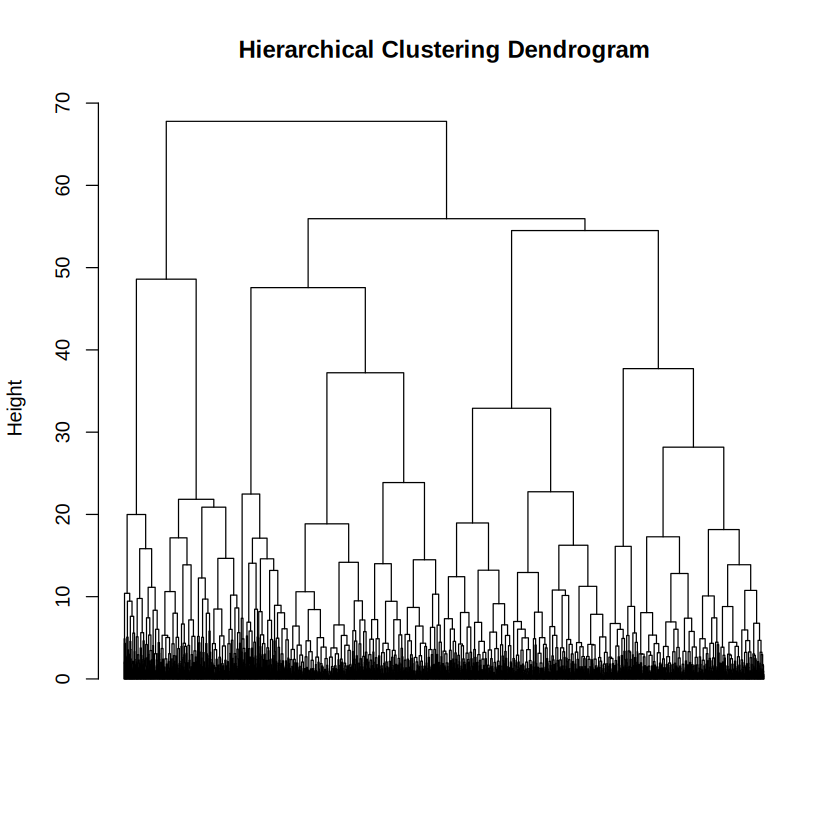

In [131]:
plot(
  hierarchical_model,
  main = "Hierarchical Clustering Dendrogram",
  xlab = "",
  sub = "",
  labels = FALSE,
  hang = -1
)

**Q9.** Divide into 3 clusters (`cutree`) and display assignments.

In [132]:
hierarchical_clusters <- cutree(
  hierarchical_model,
  k = 3
)
hierarchical_clusters

[1] 1 2 3 2 1 3 1 3 2 3 1 1 1 3 3 3 3 1 3 3 3 3 1 1 3 3 3 2 2 2 1 1 3 3 3 3 3
  [38] 3 3 1 3 3 1 1 3 3 2 3 2 3 2 2 3 1 3 3 3 3 2 3 2 3 3 3 3 3 3 3 3 3 3 3 3 3
  [75] 3 3 3 3 3 3 3 3 3 3 3 3 3 2 3 3 2 3 3 3 1 1 1 3 1 3 1 2 1 1 2 1 1 2 3 2 1
 [112] 3 1 3 3 1 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 1 1 3 1 1 2 3 3 3 3 3 3
 [149] 3 3 3 3 3 1 1 3 3 1 1 1 3 1 1 1 1 3 3 3 3 1 1 3 1 1 3 1 3 3 3 3 2 2 3 2 1
 [186] 3 3 2 3 1 2 3 3 3 3 1 2 1 3 3 3 3 3 1 1 3 3 1 1 3 1 3 3 3 3 1 2 1 3 2 3 3
 [223] 3 3 3 1 1 3 1 2 1 1 3 3 3 3 1 1 1 1 3 1 3 3 1 2 3 3 3 3 3 3 1 3 1 3 3 2 3
 [260] 3 3 2 1 3 3 1 2 3 3 3 3 2 2 3 3 2 3 3 2 3 2 3 3 3 3 1 1 1 3 2 1 3 3 3 3 3
 [297] 3 3 2 3 2 2 2 3 3 1 2 3 3 3 1 2 3 2 3 3 3 3 3 2 2 3 3 2 3 3 3 3 1 3 3 3 3
 [334] 1 1 2 3 3 2 2 3 3 1 1 1 2 1 2 1 3 1 3 3 1 3 3 1 1 3 3 3 3 3 1 1 3 2 3 3 3
 [371] 1 2 3 3 3 1 1 3 2 3 3 3 2 3 1 3 3 2 1 3 3 1 1 3 3 2 1 3 3 2 1 3 2 3 3 1 1
 [408] 1 3 1 3 1 3 1 3 3 3 2 1 1 3 1 1 2 1 1 3 1 3 3 2 1 1 3 2 1 3 3 2 3 3 3 3 3
 [445] 1 1 3 3 3 1 1 3 3 3 1 3 3 3 3 3 1 2 3 3 3 3 2 3 1 1 3 3 3 1 3 1 1 1 2 3 3
 [482] 1 1 3 3 3 3 2 3 3 3 3 1 3 3 2 3 3 3 2 3 3 1 1 2 2 2 2 2 1 2 1 1 1 3 3 1 2
 [519] 2 3 3 3 1 3 3 3 1 3 3 3 1 1 3 1 3 1 1 1 2 3 3 1 3 3 1 3 3 1 1 3 3 3 3 3 1
 [556] 1 2 3 1 1 3 3 2 3 3 1 1 1 3 3 3 3 3 1 3 3 1 1 3 3 3 2 3 3 3 3 3 3 1 3 2 3
 [593] 3 3 1 3 1 1 1 1 3 1 3 2 2 3 3 3 1 1 1 3 1 3 1 2 3 3 3 3 3 3 3 3 3 1 3 3 3
 [630] 3 3 1 1 1 1 3 1 3 3 3 3 3 3 3 1 3 3 3 1 2 1 3 1 1 3 3 3 2 1 3 1 3 3 3 1 3
 [667] 3 3 3 1 1 3 3 3 1 3 1 1 1 3 3 2 3 3 2 3 3 3 3 2 3 1 1 3 1 3 1 3 1 1 1 1 3
 [704] 1 1 1 1 1 1 3 3 3 2 1 1 2 3 3 3 3 1 1 3 2 1 3 3 1 3 3 1 1 1 1 3 2 3 1 3 1
 [741] 3 3 3 2 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3 3 3 2 3 3 1 1 1 3 2 3 3 3 3
 [778] 3 3 3 3 3 1 3 1 1 1 2 2 2 2 3 2 3 3 2 1 2 2 1 3 3 3 2 3 3 3 3 3 3 3 3 3 1
 [815] 3 3 2 3 2 3 3 2 3 3 3 3 2 3 3 3 3 3 1 1 2 3 3 3 1 3 1 3 3 3 3 1 3 3 1 3 3
 [852] 3 3 3 3 1 2 1 1 1 3 2 3 3 3 3 3 3 3 1 2 3 3 1 1 2 1 2 3 3 3 3 2 1 3 2 1 3
 [889] 3 1 3 2 1 2 2 1 1 3 2 1 1 1 3 3 3 1 1 2 3 3 3 3 3 1 1 1 1 3 3 2 1 2 1 1 1
 [926] 1 1 1 2 1 1 3 2 3 3 3 1 3 1 2 3 1 1 1 3 2 3 2 3 3 2 3 3 3 3 3 3 1 3 3 1 2
 [963] 2 3 3 1 1 3 1 3 1 3 1 3 3 2 3 2 3 1 3 1 3 3 2 3 1 3 1 1 1 2 1 3 2 3 3 3 3
[1000] 2 3 3 1 3 1 2 3 3 3 1 1 1 3 3 3 1 1 3 3 1 3 1 3 1 1 1 1 3 3 3 1 2 1 2 1 2
[1037] 3 3 3 3 3 1 3 3 3 2 3 1 3 3 3 3 3 3 3 1 3 3 3 3 2 3 2 3 2 3 3 3 3 1 3 3 1
[1074] 1 1 1 3 1 3 3 3 3 3 3 1 1 3 3 2 1 3 1 3 3 1 3 3 2 1 1 2 1 3 3 1 2 1 3 3 3
[1111] 3 3 3 3 1 1 3 1 3 1 1 1 3 3 3 2 1 3 1 2 1 2 3 1 1 3 1 1 1 1 3 3 2 3 3 3 1
[1148] 3 3 2 3 3 1 2 3 3 2 3 1 1 3 3 1 2 3 1 1 3 3 3 2 1 1 3 2 1 1 1 3 3 2 3 3 2
[1185] 3 2 3 1 1 3 2 3 2 3 3 3 2 3 1 3 3 3 3 3 1 3 1 2 2 3 1 2 2 3 3 2 3 3 3 3 3
[1222] 3 2 2 3 3 3 2 3 3 3 3 3 1 3 3 3 3 3 3 3 1 3 3 3 2 3 3 2 1 1 1 3 2 3 3 3 2
[1259] 1 3 2 2 2 3 1 1 3 3 2 3 1 3 3 3 3 3 3 3 1 3 3 3 1 2 2 1 3 3 3 3 3 3 1 2 3
[1296] 3 3 3 3 1 3 3 3 3 1 2 1 1 1 1 2 3 3 3 3 3 2 2 3 3 3 1 3 3 2 2 3 3 3 3 1 2
[1333] 3 3 3 2 1 3 1 3 2 2 1 1 1 1 1 1 3 1 2 3 3 2 3 2 1 2 3 1 3 3 1 3 2 2 2 3 3
[1370] 3 3 1 2 3 3 3 3 2 1 3 1 3 2 2 2 2 3 2 3 1 3 2 3 3 3 2 3 3 3 3 3 3 1 3 3 3
[1407] 3 3 3 3 3 1 1 1 3 2 3 2 3 3 1 3 3 1 3 3 2 3 1 3 3 1 3 3 3 3 2 1 3 1 3 1 3
[1444] 3 3 2 3 3 3 1 3 1 3 3 3 3 3 3 3 3 3 2 3 3 3 1 3 3 3 2 3 3 3 3 2 3 1 1 1 2
[1481] 1 2 1 3 2 3 3 3 3 3 3 3 1 2 1 3 3 3 3 2 3 2 2 3 2 1 3 3 3 2 3 3 3 1 1 3 3
[1518] 3 3 3 1 3 3 3 2 2 2 3 2 3 2 2 3 3 3 2 3 2 3 2 3 1 1 1 1 1 3 3 3 2 1 2 3 1
[1555] 3 2 1 1 3 1 3 3 3 2 1 2 1 3 2 2 2 3 3 3 3 3 1 3 2 3 2 3 3 2 2 3 2 3 3 1 1
[1592] 2 3 3 3 3 3 3 3 1 1 3 3 3 3 3 3 3 3 3 2 1 3 3 1 3 3 3 1 3 3 2 3 3 2 3 1 1
[1629] 3 3 3 1 3 2 1 3 2 3 1 3 3 3 1 2 1 3 2 2 2 3 2 1 3 3 3 3 1 2 2 1 3 3 1 3 3
[1666] 1 3 3 1 3 1 1 2 2 1 3 3 3 3 3 3 3 3 2 3 2 3 3 1 2 3 3 3 3 3 3 2 1 1 2 3 2
[1703] 1 2 2 3 3 3 3 3 1 3 3 3 1 3 3 3 1 1 1 2 3 3 3 1 3 3 3 3 1 3 1 1 2 3 2 2 3
[1740] 3 3 3 3 3 1 3 2 1 1 2 3 1 1 3 3 2 3 3 2 2 1 3 3 3 3 3 1 3 2 3 2 1 1 3 3 3
[1777] 2 3 3 3 3 3 2 1 3 2 3 3 3 2 2 3 3 1 3 2 2 3 3 3 3 3 1 2 1 3 2 3 1 2 3 3 3
[1814] 3 1 2 2 3 3 2 3 3 3 3 3 3 2

**Q10.** Number of samples in each cluster.

In [133]:
table(hierarchical_clusters)

hierarchical_clusters
   1    2    3 
1041  606 1665 

---
# ASSESSMENT IX — Principal Component Analysis

**Q1.** Load the dataset and load ggplot2, ggfortify, FactoMineR, factoextra.

In [134]:
packages <- c("ggplot2", "ggfortify", "FactoMineR", "factoextra", "readxl", "ggrepel")

for (p in packages) {
  if (!requireNamespace(p, quietly = TRUE)) install.packages(p)
  library(p, character.only = TRUE)
}

data <- read_excel(data_path)
data <- as.data.frame(data)

Welcome to factoextra!

Want to learn more? See two factoextra-related books at https://www.datanovia.com/library/principal-component-methods



**Q2.** Number of rows and columns.

In [135]:
cat("Number of rows:", nrow(data), "\n")
cat("Number of columns:", ncol(data), "\n")

Number of rows: 9120 
Number of columns: 11 


**Q3.** Extract numeric columns, clean, and normalize into `data_scaled`.

In [146]:
numeric_data <- data[, sapply(data, is.numeric), drop = FALSE]
numeric_data <- na.omit(numeric_data)
numeric_data <- numeric_data[, sapply(numeric_data, function(x) sd(x) > 0), drop = FALSE]
data_scaled <- scale(numeric_data)
head(data_scaled)

,rownames,kids,age,education,year,siblings,agefirstbirth
2,-1.553644,-1.0798386,-1.1244886,0.03689781,1.179615,-0.01886157,-0.7471851
3,-1.553346,-1.0798386,0.3615011,-3.88223089,1.179615,-0.90705365,0.8991697
4,-1.553049,-0.3851173,0.4803802,1.10575110,1.179615,-0.90705365,-0.1298021
5,-1.552751,-0.3851173,1.3125344,-0.31938661,1.179615,0.57326649,1.3107584
9,-1.551560,-1.0798386,-0.8272906,-0.31938661,1.179615,-1.20311768,-0.3355964
10,-1.551262,0.3096041,0.1237427,-0.31938661,1.179615,-0.90705365,-0.5413908


**Q4.** PCA on `data_scaled` with summary.

In [137]:
pca <- prcomp(data_scaled, center = FALSE, scale. = FALSE)
print(summary(pca))

Importance of components:
                          PC1    PC2    PC3    PC4    PC5     PC6     PC7
Standard deviation     1.3534 1.3020 1.0692 0.9597 0.8346 0.67463 0.50712
Proportion of Variance 0.2617 0.2422 0.1633 0.1316 0.0995 0.06502 0.03674
Cumulative Proportion  0.2617 0.5038 0.6672 0.7987 0.8982 0.96326 1.00000


**Q5.** Scree plot (percentage of variance with data labels, y-axis 0–60).

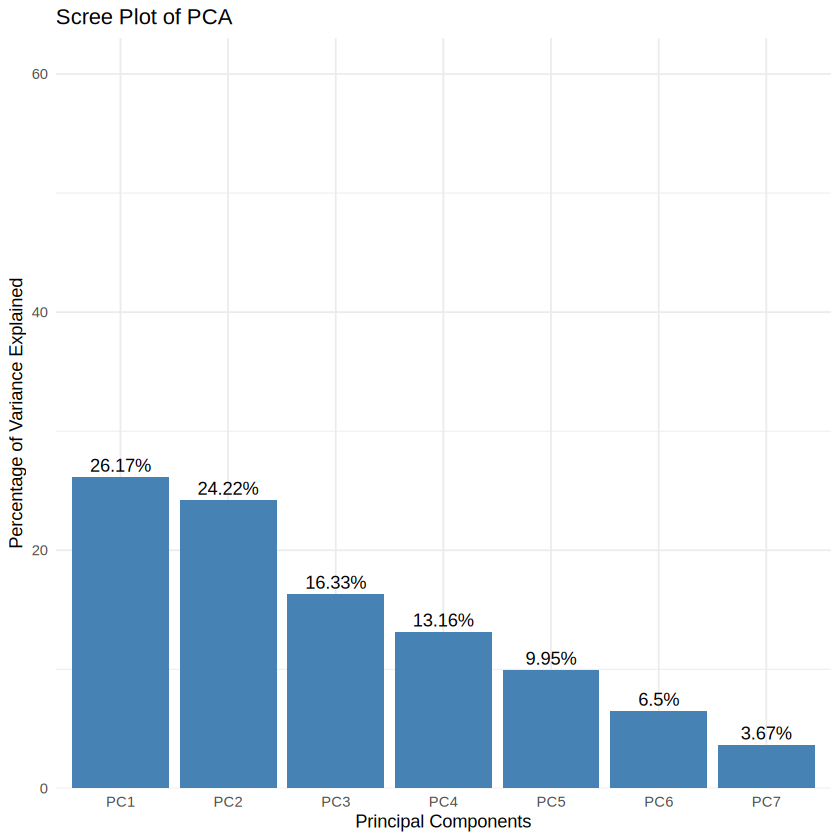

In [138]:
variance <- (pca$sdev^2 / sum(pca$sdev^2)) * 100

scree_data <- data.frame(
  Component = factor(paste0("PC", seq_along(variance)),
                     levels = paste0("PC", seq_along(variance))),
  Variance = variance
)

ggplot(scree_data, aes(x = Component, y = Variance)) +
  geom_col(fill = "steelblue") +
  geom_text(aes(label = paste0(round(Variance, 2), "%")), vjust = -0.4) +
  scale_y_continuous(limits = c(0, 60), expand = expansion(mult = c(0, 0.05))) +
  labs(title = "Scree Plot of PCA", x = "Principal Components",
       y = "Percentage of Variance Explained") +
  theme_minimal()

**Q6.** PCA biplot.

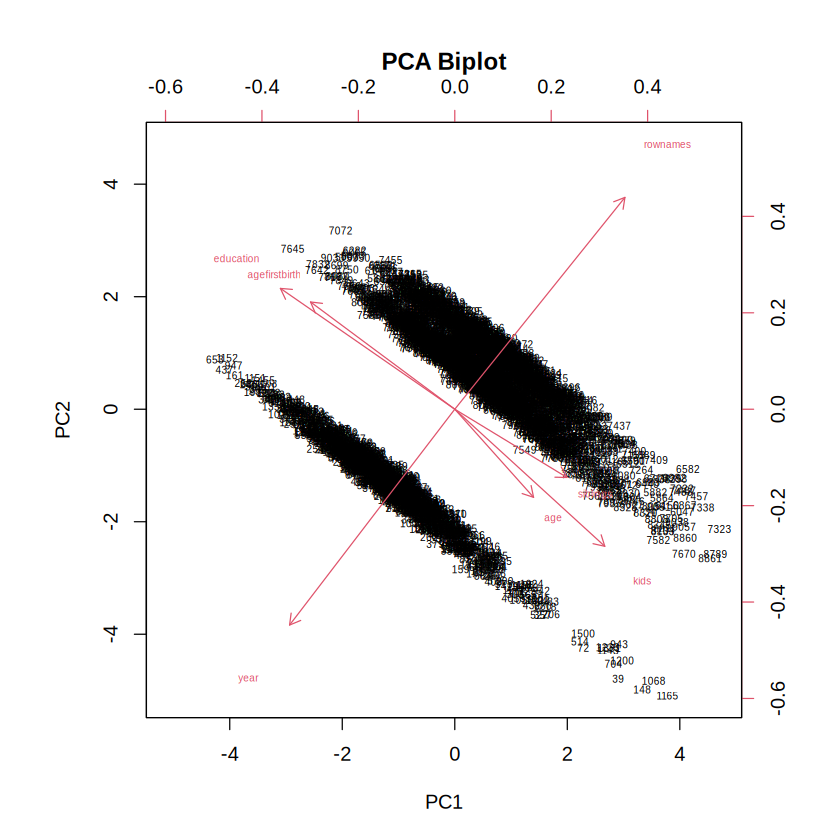

In [139]:
biplot(
  pca,
  choices = c(1, 2),
  scale = 0,
  cex = 0.5,
  main = "PCA Biplot"
)

**Q7.** Extract PCA scores into `pca_scores` and display the first six rows.

In [140]:
pca_scores <- as.data.frame(pca$x)
print(head(pca_scores, 6))

          PC1        PC2        PC3        PC4        PC5         PC6       PC7
2  -1.5830899 -1.0656197 -1.6905501  0.0160127  0.2973473  0.36241965 0.2759196
3  -0.3815011 -2.0175716 -0.2309439 -0.2382733  3.8687908 -1.57541361 0.1684099
4  -1.9572824 -1.0151375  0.4051823  0.6907186 -0.1301092  0.80749951 0.2703798
5  -1.2510323 -1.5128808  1.2554845 -1.3180859  0.7674381 -0.01676929 0.2561139
9  -1.8587500 -0.9199525 -1.1014458  0.8222021  1.0322036 -0.02640395 0.2341188
10 -0.9608518 -1.7404341 -0.1116711  0.9907383  0.3414108 -0.03597248 0.2503922


**Q8.** Scatter plot of PC1 vs PC2 (blue circular points, registration number in title).

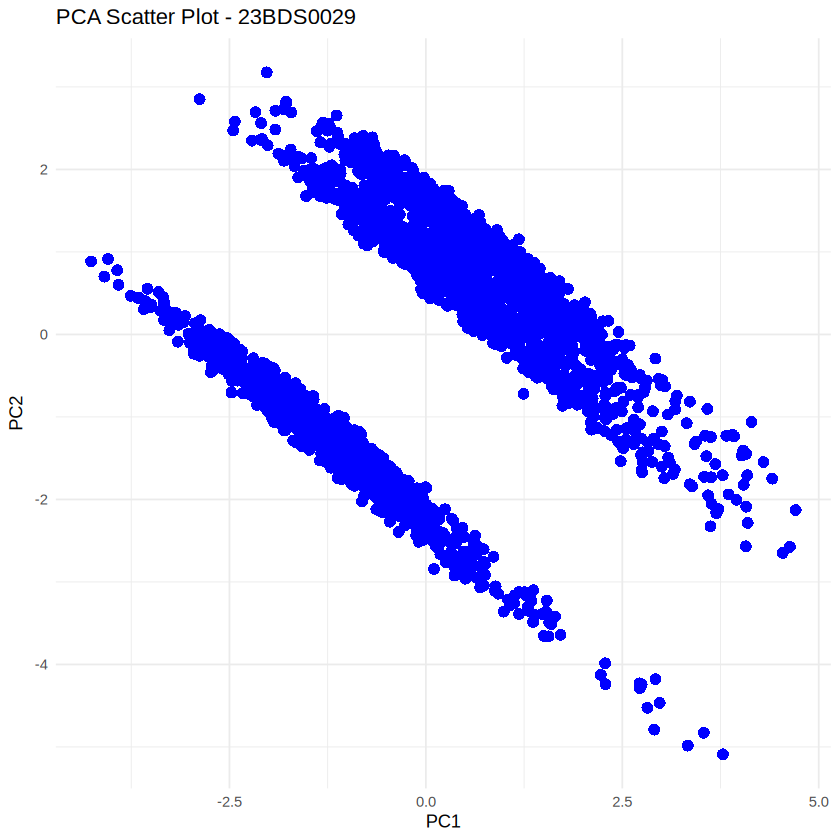

In [141]:
ggplot(pca_scores, aes(x = PC1, y = PC2)) +
  geom_point(color = "blue", shape = 16, size = 3) +
  labs(
    title = "PCA Scatter Plot - 23BDS0029",
    x = "PC1",
    y = "PC2"
  ) +
  theme_minimal()